
# Credit Pre-Screening Engine — Loan Intake Optimisation

### Calibo AI Academy | Phase 2 — Mini Use Case 02

**Industry:** BFSI — Retail Lending (Personal Loans)

**Batch:** Path 3 — Online Batch

**Modules Covered:** Supervised Learning — Parts 1 & 2, Unsupervised Learning, Model Selection and Validation

---

## 1. Project Overview

This project focuses on developing a Credit Pre-Screening Engine to help a bank improve its personal loan application review process using machine learning.

The bank receives approximately 3,000 loan applications per month, and each application takes a credit analyst around 25 minutes to review manually. The objective is to use six months of historical application data and final credit-team decisions to identify clear-cut declines and potential approvals, allowing analysts to focus on applications that require human judgement.

## 2. Business Problem Statement

The bank wants to understand whether historical loan application data can be used to build a reliable pre-screening model that reduces manual review workload while controlling credit risk.

The solution must identify applications suitable for preliminary screening, minimise wrongly declined creditworthy applicants, avoid fast-tracking risky applications, and support transparent and fair decision-making.

## 3. Project Objectives

- Understand the business problem and historical loan application data.
- Inspect, clean and preprocess the dataset with justified decisions.
- Analyse historical approval patterns and important credit-risk factors.
- Engineer FOIR, loan-to-income and new-to-credit features.
- Build and evaluate a Logistic Regression baseline classifier.
- Select an auto-decline threshold that satisfies the bank's 5% risk limit.
- Examine fairness across gender and potential proxy variables.
- Build a reusable machine learning pipeline.
- Compare four classification models using five-fold stratified cross-validation.
- Design a two-lane pre-screening system with auto-decline, analyst-review and fast-track lanes.
- Compare models based on performance, explainability, risk and business impact.
- Provide actionable recommendations for the Credit Policy Analyst.
- Apply K-Means clustering as an optional extension to identify applicant segments.

## 4. Tools and Technologies

- Python
- Google Colab / Jupyter Notebook
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn

## 5. Dataset Overview

**Dataset file:** `MUC02_Credit_PreScreening_Dataset.csv`

The dataset contains 12,000 personal loan applications received between April and September 2026. Each row represents one application, and the `decision` column records the final decision made by the bank's credit team.

The dataset includes applicant demographics, employment details, income, existing financial obligations, credit history, requested loan information and the final credit decision.

## 6. Expected Deliverables

1. A Jupyter Notebook covering Steps 5.1–5.11, with Step 5.12 included if attempted.
2. A completed CBIM Problem Canvas, placed separately at the top of the notebook or submitted as a separate document.
3. A one-page written insight summary of no more than 400 words.
4. A fully tested notebook that runs from beginning to end without errors.

## 7. Project Approach

The project will follow a structured workflow covering business understanding, data preparation, feature engineering, supervised learning, model validation, threshold selection, fairness assessment, unsupervised learning as an optional extension, and business recommendations.

**Important principle:** The goal is not simply to achieve the highest accuracy. The goal is to develop a useful and explainable pre-screening approach that improves loan intake efficiency while respecting the bank's risk limits.

Model predictions will support preliminary screening and will not be used as the sole basis for final loan approval or rejection.



# CBIM Problem Canvas

## 1. Situation

A mid-size private bank in India provides unsecured personal loans to salaried employees, self-employed professionals, business owners and gig workers. The bank receives approximately 3,000 applications every month, and each application takes around 25 minutes for a credit analyst to review manually.

## 2. Complication

Manual reviews consume significant analyst time, including time spent on applications that may be declined due to clear credit-risk indicators. This reduces the time available for applications that need detailed investigation and human judgement. The bank wants to improve efficiency without wrongly declining creditworthy applicants or fast-tracking risky applications.

## 3. Question

Using six months of historical loan applications and their final credit-team decisions, how much of the manual review queue can a pre-screening model safely reduce while meeting the bank's risk limits?

## 4. SSOT (Single Source of Truth)

The provided dataset, `MUC02_Credit_PreScreening_Dataset.csv`, is the single source of truth for this analysis. Each row represents one loan application, and the `decision` column contains the historical final decision made by the credit team: Approved or Declined.

## 5. Success Definition

The pre-screening solution should reduce manual reviews while satisfying both business risk limits:

- No more than 5% of applications in the auto-decline lane should have been historically approved.
- No more than 5% of applications in the fast-track lane should have been historically declined.

The solution should also demonstrate useful predictive performance, explainability, fairness awareness and measurable monthly analyst-time savings.

## 6. Primary Stakeholder

The primary stakeholder is the Credit Policy Analyst, who must present a clear and defensible recommendation to the Head of Retail Lending. Credit analysts, loan applicants and the bank are also affected by the screening decisions.



# Step 5.1 — Load, Inspect, and Clean the Dataset

## Objective

The first step is to load the credit pre-screening dataset and understand its structure before making any changes.

## Why are we doing this?

Before building a machine learning model, we need to understand how many applications are present, what information each column contains, whether any values are missing, and whether duplicate records exist.

We will also calculate the historical approval rate to understand the bank's existing lending decisions.

## Business Relevance

Checking the data quality helps us avoid incorrect conclusions and unreliable predictions. We will investigate missing monthly income, missing credit scores, and unusually high income values before deciding how to handle them.

**Important:** Applicants with missing credit scores should not automatically be removed because they may be new-to-credit applicants with no previous credit history.


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [3]:

df = pd.read_csv("MUC02_Credit_PreScreening_Dataset.csv")


In [4]:

df.shape


(12000, 19)


### Understanding the Dataset Structure

The first five rows help us understand how individual loan applications are recorded in the dataset. Each row represents one application, and each column contains information such as applicant details, income, credit history, loan details, or the final credit decision.

In the next step, we will examine the column names and data types to identify numerical and categorical variables. This is important because different types of data may require different preprocessing methods before machine learning.


In [5]:

df.head()


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined



### Checking Column Names and Data Types

In this step, we will examine all the columns and their data types using Pandas.

Numerical columns contain values such as age, income, credit score and loan amount. Categorical columns contain labels such as gender, employment type, city and loan decision.

Understanding these data types helps us identify which preprocessing methods may be required before building the machine learning model.


In [6]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   application_id         12000 non-null  str    
 1   application_date       12000 non-null  str    
 2   age                    12000 non-null  int64  
 3   gender                 12000 non-null  str    
 4   city                   12000 non-null  str    
 5   city_tier              12000 non-null  int64  
 6   employment_type        12000 non-null  str    
 7   years_in_current_job   12000 non-null  float64
 8   monthly_income         11559 non-null  float64
 9   existing_emi           12000 non-null  float64
 10  credit_score           10961 non-null  float64
 11  credit_history_months  12000 non-null  int64  
 12  num_active_loans       12000 non-null  int64  
 13  delinquencies_24m      12000 non-null  int64  
 14  loan_purpose           12000 non-null  str    
 15  loan_amount  


### Checking Missing Values

Missing values occur when information is not available for some loan applications. Before building a machine learning model, we need to identify which columns contain missing data and how many values are missing.

From the dataset information, monthly_income and credit_score contain missing values. Missing monthly income may affect affordability calculations, while a missing credit score may indicate an applicant with no established credit history.

We will examine the exact missing-value counts before deciding how to handle them. We should not automatically remove applicants with missing credit scores because they may be new-to-credit applicants.


In [7]:
df.isnull().sum()

application_id              0
application_date            0
age                         0
gender                      0
city                        0
city_tier                   0
employment_type             0
years_in_current_job        0
monthly_income            441
existing_emi                0
credit_score             1039
credit_history_months       0
num_active_loans            0
delinquencies_24m           0
loan_purpose                0
loan_amount                 0
tenure_months               0
proposed_emi                0
decision                    0
dtype: int64


### Checking Duplicate Records

Duplicate records occur when the same record appears more than once in a dataset. They can affect our analysis and may cause the same loan application to be counted multiple times.

Before removing anything, we will count the duplicate rows. If duplicates exist, we will investigate and decide whether they should be removed.


In [8]:
df.duplicated().sum()

0


### Understanding the Loan Decision Distribution

The decision column contains the historical loan outcomes: Approved or Declined. We need to understand how many applications fall into each category and calculate the overall approval rate.

This helps us understand the bank's existing lending decisions and the balance between approved and declined applications. We will use this information as a baseline for evaluating our pre-screening model.


In [9]:
decision_counts = df["decision"].value_counts()

approval_rate = (df["decision"].eq("Approved").mean()) * 100
decline_rate = (df["decision"].eq("Declined").mean()) * 100

print("Loan Decision Counts:")
print(decision_counts)

print(f"\nOverall Approval Rate: {approval_rate:.2f}%")
print(f"Overall Decline Rate: {decline_rate:.2f}%")

Loan Decision Counts:
decision
Approved    6353
Declined    5647
Name: count, dtype: int64

Overall Approval Rate: 52.94%
Overall Decline Rate: 47.06%


Interpretation of the results
- Total applications: 12,000
- Approved: 6,353 applications (52.94%)
- Declined: 5,647 applications (47.06%)
Business understanding: Nearly 47% of applications were declined historically. The goal of our project is to identify clear declines and suitable approvals so the bank can reduce manual review time while keeping lending decisions safe.


### Investigating Missing Monthly Income by Employment Type

Monthly income is important for assessing whether an applicant can afford a loan. Missing income values may affect calculations such as FOIR and loan-to-income ratio.

We will check how missing monthly income is distributed across employment types. This will help us understand whether missing income is concentrated in a particular group and choose a suitable imputation method based on the evidence.


In [10]:
missing_income_by_employment = df.groupby("employment_type")["monthly_income"].apply(
    lambda x: x.isnull().sum()
)

total_by_employment = df["employment_type"].value_counts()

missing_income_summary = pd.DataFrame({
    "Total Applications": total_by_employment,
    "Missing Monthly Income": missing_income_by_employment
})

missing_income_summary["Missing Income Percentage"] = (
    missing_income_summary["Missing Monthly Income"]
    / missing_income_summary["Total Applications"] * 100
).round(2)

missing_income_summary

,Total Applications,Missing Monthly Income,Missing Income Percentage
employment_type,,,
Business Owner,1749,227,12.98
Gig / Contract,1766,11,0.62
Salaried,7057,49,0.69
Self-Employed Professional,1428,154,10.78


Interpretation of the results
- Business Owner: 12.98% missing income — the highest.
- Self-Employed Professional: 10.78% missing income.
- Salaried: 0.69% missing income.
- Gig / Contract: 0.62% missing income.
Business understanding: Missing income is much more common among business owners and self-employed professionals. We should investigate this pattern before selecting an imputation method. Using the overall median without considering employment type could hide differences between these groups.


### Investigating Missing Credit Scores and Credit History

Credit scores help the bank understand an applicant's creditworthiness. However, a missing credit score does not always mean the data is incorrect. Some applicants may be new-to-credit and may not have an established credit history.

We will compare applications with missing credit scores against credit_history_months. This will help us understand whether these applicants have no credit history or whether their credit score is missing despite having an existing credit history.

We will not automatically remove these applications because new-to-credit applicants are also important for lending decisions.


In [11]:
missing_score_summary = df.groupby(
    df["credit_score"].isnull()
)["credit_history_months"].agg(
    Total_Applications="count",
    Minimum_History_Months="min",
    Maximum_History_Months="max",
    Zero_History_Count=lambda x: (x == 0).sum()
)

missing_score_summary.index = [
    "Credit Score Available",
    "Credit Score Missing"
]

missing_score_summary

,Total_Applications,Minimum_History_Months,Maximum_History_Months,Zero_History_Count
Credit Score Available,10961,6,395,0
Credit Score Missing,1039,0,0,1039


Interpretation of the results
- Credit score available: 10,961 applications.
- Credit score missing: 1,039 applications.
- All 1,039 applications with missing credit scores have credit_history_months = 0.
- Applicants with an available credit score have at least 6 months of credit history.
Business understanding: The missing credit scores are associated with applicants who have no established credit history. These are new-to-credit (NTC) applicants, not random missing values in this dataset. We should retain these applications and create an is_ntc feature to identify them, as required by the project.


### Investigating Unusually High Monthly Income

Monthly income is used to evaluate loan affordability. If some applicants have entered annual income instead of monthly income, their values may be unusually high and could affect the model.

We will inspect the maximum monthly income and the highest income records before deciding whether any values need correction. We should not change or remove values without evidence that they are incorrect.


In [12]:
df["monthly_income"].max()

1656000.0

Interpretation
- The maximum value is ₹16,56,000 per month.
- This may be a genuine high income or a possible data-entry issue, such as annual income entered as monthly income.
- We need to inspect the highest income records before deciding whether any correction is justified.


### Inspecting the Highest Monthly Income Records

The maximum monthly income is ₹16,56,000. Before making any changes, we will inspect the highest income records along with employment type and other relevant details.

This will help us check whether these values appear plausible and whether there is evidence of annual income being entered as monthly income. We will document any cleaning decision based on the observed data rather than changing values based only on their size.


In [68]:
# Step 5.1 — High Monthly Income Distribution

income = df["monthly_income"]

thresholds = [100000, 200000, 300000, 400000, 500000, 700000, 1000000]

income_summary = pd.DataFrame({
    "Monthly_Income_Above": [f"₹{x:,.0f}" for x in thresholds],
    "Applicant_Count": [(income > x).sum() for x in thresholds]
})

display(income_summary)

print("Missing income values:", income.isna().sum())
print("Highest recorded monthly income: ₹{:,.0f}".format(income.max()))

,Monthly_Income_Above,Applicant_Count
0,"₹100,000",1356
1,"₹200,000",93
2,"₹300,000",28
3,"₹400,000",17
4,"₹500,000",13
5,"₹700,000",10
6,"₹1,000,000",4


Missing income values: 441
Highest recorded monthly income: ₹1,656,000


#### Step 5.1 — High-Income Distribution: Findings

The dataset contains **13 applications with recorded monthly incomes above ₹5 lakh**, including **4 above ₹10 lakh**. The maximum recorded monthly income is **₹16.56 lakh**.

These values are unusually high and could reflect genuine high earnings or possible income-unit entry errors. However, the dataset does not provide sufficient evidence to distinguish between these possibilities.

**Cleaning decision:** Retain the original income values, document them for further investigation, and avoid unsupported corrections such as dividing them by 12 or removing the records.

This analysis is exploratory and does not introduce a fixed income-based approval rule.


### Data Quality Findings and Initial Cleaning Decisions

The dataset contains 12,000 applications and has no exact duplicate rows. Missing values occur only in monthly_income (441 records) and credit_score (1,039 records). Missing monthly income is concentrated among Business Owners and Self-Employed Professionals, so we will investigate a suitable imputation approach. All applications with missing credit scores have zero credit history months, so we will retain them and identify them as new-to-credit applicants. The maximum monthly income is ₹16,56,000; we have not changed these high values because the available evidence does not prove that they are incorrect.

These findings will guide the next data-cleaning steps before feature engineering and model building.



### Planning the Missing-Value Treatment

Before cleaning the dataset, we need to decide how to handle the missing monthly_income and credit_score values.

For monthly_income, we will compare suitable imputation options and consider the differences between employment types. For credit_score, we will preserve the new-to-credit information using the is_ntc feature and impute missing scores only when preparing the model features.

We will also check the dataset instructions before making any changes to unusually high income values. Our goal is to prepare reliable data without removing useful loan applications or making unsupported corrections.


In [14]:
df.groupby("employment_type")["monthly_income"].agg(
    ["count", "median", "mean", "min", "max"]
).round(2)

,count,median,mean,min,max
employment_type,,,,,
Business Owner,1522,69500.0,79441.52,12000.0,330000.0
Gig / Contract,1755,28000.0,32152.14,12000.0,170000.0
Salaried,7008,50000.0,58827.34,12000.0,1656000.0
Self-Employed Professional,1274,75000.0,84443.09,12000.0,349000.0


Interpretation of the results
- Business Owner: Median income ₹69,500.
- Gig / Contract: Median income ₹28,000.
- Salaried: Median income ₹50,000.
- Self-Employed Professional: Median income ₹75,000.
The median incomes differ across employment types. Also, the Salaried group has a much higher maximum income than its median, suggesting that its income distribution may contain extreme values.

Cleaning decision: We can use the median income within each employment type to fill missing monthly income values. This preserves the differences between employment groups and is less affected by extreme values than the mean.


### Handling Missing Monthly Income

Our investigation shows that typical monthly income differs across employment types. We will fill missing monthly_income values using the median income of the applicant's employment type.

The median is suitable because it is less affected by unusually high values than the mean. This approach allows us to retain applications with missing income instead of deleting them.

We will preserve the original dataset and create a cleaned working copy so that the changes are clear and reproducible.


In [15]:
# Keep the original dataset unchanged
df_clean = df.copy()

# Do not impute income using the full dataset.
# Income medians will be learned from training data
# during the modelling stage.

print(
    "Missing monthly_income values:",
    df_clean["monthly_income"].isna().sum()
)

print(
    "Missing credit_score values:",
    df_clean["credit_score"].isna().sum()
)

print(
    "Dataset shape:",
    df_clean.shape
)

Missing monthly_income values: 441
Missing credit_score values: 1039
Dataset shape: (12000, 19)


**Interpretation**

- Missing monthly incomes identified: **441**.
- Missing monthly incomes after initial inspection: **441**.
- Income values have intentionally been preserved at this stage.
- Employment-specific median imputation will be performed in Step 5.4 using training-data statistics only.
- All **12,000 applications** have been retained.

**Business understanding:** This approach preserves incomplete applications while preventing held-out test records from influencing income-imputation statistics.


### Handling Missing Credit Scores

Our investigation showed that all 1,039 applications with missing credit scores have zero credit history months. These applicants are new-to-credit applicants.

We should not treat them as ordinary records with missing information or remove them from the dataset. We will create an is_ntc feature to identify applicants with no credit score. Later, when preparing the model, we will impute missing credit scores using the median of the available scores while retaining the is_ntc indicator.

This allows the model to use credit score information where available while preserving the distinction between applicants with and without established credit history.


In [16]:
df_clean["is_ntc"] = df_clean["credit_score"].isnull().astype(int)

print("New-to-credit applicants:", df_clean["is_ntc"].sum())
print("Applicants with an available credit score:", (df_clean["is_ntc"] == 0).sum())
print("Missing credit scores remaining:", df_clean["credit_score"].isnull().sum())

New-to-credit applicants: 1039
Applicants with an available credit score: 10961
Missing credit scores remaining: 1039


Interpretation
- New-to-credit applicants: 1,039 (is_ntc = 1)
- Applicants with an available credit score: 10,961 (is_ntc = 0)
- Missing credit scores remaining: 1,039
We are intentionally keeping those missing credit scores for now. The is_ntc feature preserves the important information that these applicants have no established credit history.

### Verifying the Initial Cleaning Results

At this stage, we have retained all **12,000 applications** without imputing the **441 missing monthly income values**.

We have identified **1,039 new-to-credit applicants** using the `is_ntc` indicator while preserving their missing credit scores.

Monthly income will be imputed in Step 5.4 using employment-specific medians learned exclusively from training data. The verification below confirms the remaining missing values and dataset dimensions before modelling.

In [17]:
print("Dataset shape:", df_clean.shape)

print("\nMissing values after initial cleaning:")
print(df_clean.isnull().sum())

print("\nTotal missing values:", df_clean.isnull().sum().sum())

Dataset shape: (12000, 20)

Missing values after initial cleaning:
application_id              0
application_date            0
age                         0
gender                      0
city                        0
city_tier                   0
employment_type             0
years_in_current_job        0
monthly_income            441
existing_emi                0
credit_score             1039
credit_history_months       0
num_active_loans            0
delinquencies_24m           0
loan_purpose                0
loan_amount                 0
tenure_months               0
proposed_emi                0
decision                    0
is_ntc                      0
dtype: int64

Total missing values: 1480



### Checking the Application Date Format

The application_date column currently has a text data type. Converting it to a proper date format would allow us to sort and analyze applications by date.

However, application_date is not one of the specified model features. We will inspect its format and keep it available for reporting and identifying recent applications, while excluding it from the model features as required by the project instructions.


In [18]:
df_clean["application_date"] = pd.to_datetime(
    df_clean["application_date"],
    errors="coerce"
)

print("Application date data type:", df_clean["application_date"].dtype)
print("Invalid or missing dates:", df_clean["application_date"].isnull().sum())

print("\nEarliest application date:", df_clean["application_date"].min())
print("Latest application date:", df_clean["application_date"].max())

Application date data type: datetime64[us]
Invalid or missing dates: 0

Earliest application date: 2026-04-01 00:00:00
Latest application date: 2026-09-30 00:00:00


Interpretation of the results
- Data type: datetime64[us] — the application date is now stored as a date/time value.
- Invalid or missing dates: 0.
- Earliest date: 1 April 2026.
- Latest date: 30 September 2026.
Business understanding: The dataset covers six months of loan applications, from April through September 2026, matching the project brief. We can use the date column for reporting and identifying recent applications, but we will exclude it from model features to follow the instructions.

### Step 5.1 — Data Inspection and Initial Cleaning Summary

The dataset contains 12,000 loan applications and 19 original columns. No duplicate rows were found. The historical approval rate is **52.94%**, while the decline rate is **47.06%**.

We identified **441 missing monthly income values** and preserved them for training-only, employment-specific median imputation in Step 5.4 to avoid data leakage.

We retained **1,039 applicants with missing credit scores**, associated with zero credit-history months, and flagged them using the `is_ntc` indicator during feature engineering in Step 5.3.

The highest recorded monthly income is **₹16,56,000**. We retained this value because there is insufficient evidence to classify it as an error. We also converted `application_date` into datetime format and found no invalid dates.

These checks prepare the dataset for credit-band analysis, affordability feature engineering, and predictive modelling.

In [19]:
# Preserve original data for leakage-safe preprocessing
df_clean = df.copy()

# Do not calculate income medians before train-test splitting
print("Total applications:", len(df_clean))
print("Missing monthly incomes:", df_clean["monthly_income"].isna().sum())
print("Missing credit scores:", df_clean["credit_score"].isna().sum())

Total applications: 12000
Missing monthly incomes: 441
Missing credit scores: 1039


In [20]:
print("Current missing incomes:",
      df_clean["monthly_income"].isna().sum())

print("\nOriginal affordability columns:")
print(df_clean[
    ["monthly_income", "existing_emi",
     "proposed_emi", "loan_amount"]
].isna().sum())

print("\nIncome values equal original data:",
      df_clean["monthly_income"].equals(df["monthly_income"]))

Current missing incomes: 441

Original affordability columns:
monthly_income    441
existing_emi        0
proposed_emi        0
loan_amount         0
dtype: int64

Income values equal original data: True



## Step 5.2 — Analyze Credit Score Groups and Approval Rates

Credit score is an important factor in loan decisions because it helps the bank understand an applicant's credit history. We will group applicants into the credit-score ranges specified in the project instructions and calculate the historical approval rate for each group.

Applicants without a credit score will be placed in a separate No score group. This is important because they may be new-to-credit applicants rather than applicants with a low credit score.

We will also compare approval rates across employment types. These comparisons will help us understand historical lending patterns and identify groups that may require closer attention during pre-screening.


In [21]:
def group_credit_score(score):
    if pd.isna(score):
        return "No score"
    elif score < 600:
        return "Below 600"
    elif score < 650:
        return "600–649"
    elif score < 700:
        return "650–699"
    elif score < 750:
        return "700–749"
    elif score < 800:
        return "750–799"
    else:
        return "800+"

df_clean["credit_score_group"] = df_clean["credit_score"].apply(
    group_credit_score
)

df_clean["credit_score_group"].value_counts()

credit_score_group
700–749      3377
650–699      2529
750–799      2526
800+         1350
No score     1039
600–649       933
Below 600     246
Name: count, dtype: int64

Interpretation of the results
- 700–749: 3,377 applications — the largest group.
- 650–699: 2,529 applications.
- 750–799: 2,526 applications.
- 800+: 1,350 applications.
- No score: 1,039 applications.
- 600–649: 933 applications.
- Below 600: 246 applications — the smallest group.
These are the application counts, not approval rates. Next, we'll calculate the percentage approved in each group to understand how historical decisions vary by credit score.


### Calculating Approval Rates by Credit Score Group

Now that we have created the required credit-score groups, we will calculate the number of approved applications and the approval rate within each group.

The approval rate is the percentage of applications in a group that were approved. Comparing these rates will help us identify whether historical approvals generally increase with credit score and how the bank has treated applicants with no credit score.

We will also create a chart so the differences between the groups are easier to understand.


In [22]:
credit_score_approval = df_clean.groupby("credit_score_group")["decision"].agg(
    Total_Applications="count",
    Approved=lambda x: (x == "Approved").sum()
)

credit_score_approval["Approval_Rate_Pct"] = (
    credit_score_approval["Approved"]
    / credit_score_approval["Total_Applications"] * 100
).round(2)

credit_score_approval

,Total_Applications,Approved,Approval_Rate_Pct
credit_score_group,,,
600–649,933,30,3.22
650–699,2529,822,32.50
700–749,3377,1836,54.37
750–799,2526,1950,77.20
800+,1350,1150,85.19
Below 600,246,5,2.03
No score,1039,560,53.90


Interpretation of the results
- Below 600: Only 2.03% approved.
- 600–649: Only 3.22% approved.
- 650–699: 32.50% approved.
- 700–749: 54.37% approved.
- 750–799: 77.20% approved.
- 800+: 85.19% approved.
- No score: 53.90% approved.
Business understanding: Approval rates generally increase with credit score. Applicants below 650 have very low historical approval rates, while applicants scoring 750 or above have much higher approval rates. Interestingly, applicants with no credit score have a 53.90% approval rate, so we should not automatically treat them like low-score applicants.

These are historical patterns, not proof that credit score alone determines approval.

In [69]:
ntc = df_clean[df_clean["is_ntc"] == 1]

print("NTC applicants:", len(ntc))
print("NTC applicants with existing EMI:", (ntc["existing_emi"] > 0).sum())
print("NTC applicants with zero EMI:", (ntc["existing_emi"] == 0).sum())

NTC applicants: 1039
NTC applicants with existing EMI: 0
NTC applicants with zero EMI: 1039



### Visualizing Approval Rates by Credit Score Group

A bar chart will make it easier to compare the historical approval rates across credit-score groups.

We will plot the approval rate for each group, including No score, so we can clearly see where approval rates are low or high. This visualization will help us communicate the historical lending pattern and support our later model and threshold decisions.


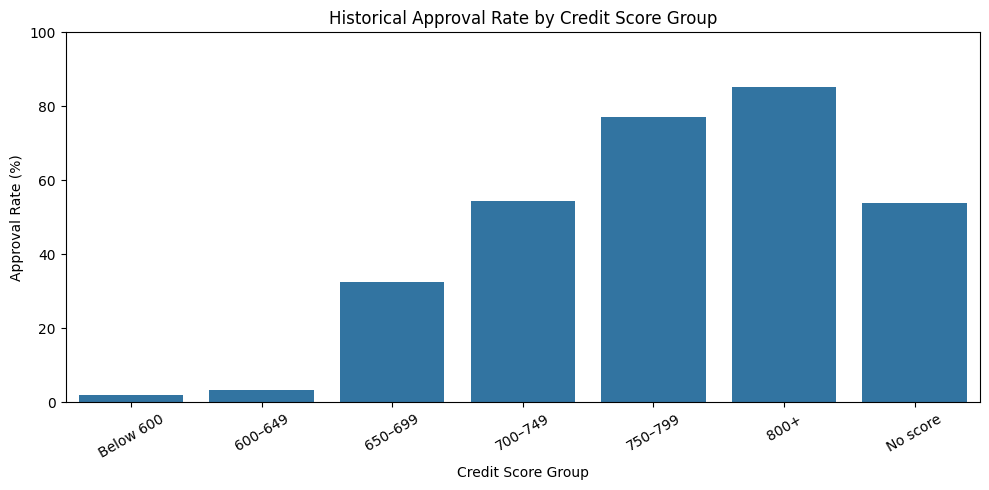

In [23]:
score_order = [
    "Below 600", "600–649", "650–699",
    "700–749", "750–799", "800+", "No score"
]

plot_data = credit_score_approval.reindex(score_order)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=plot_data.index,
    y=plot_data["Approval_Rate_Pct"]
)

plt.title("Historical Approval Rate by Credit Score Group")
plt.xlabel("Credit Score Group")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


### Analyzing Approval Rates by Employment Type

Employment type may be related to income stability and how the bank evaluates loan applications. We will calculate the number of applications and historical approval rate for each employment type.

This comparison will help us understand whether the bank's historical decisions differ between Salaried applicants, Self-Employed Professionals, Business Owners, and Gig / Contract workers. We will use the results to identify patterns, not to assume that employment type alone determines approval.


In [24]:
employment_approval = df_clean.groupby("employment_type")["decision"].agg(
    Total_Applications="count",
    Approved=lambda x: (x == "Approved").sum()
)

employment_approval["Approval_Rate_Pct"] = (
    employment_approval["Approved"]
    / employment_approval["Total_Applications"] * 100
).round(2)

employment_approval

,Total_Applications,Approved,Approval_Rate_Pct
employment_type,,,
Business Owner,1749,895,51.17
Gig / Contract,1766,617,34.94
Salaried,7057,4119,58.37
Self-Employed Professional,1428,722,50.56


Interpretation of the results
- Salaried: 58.37% approval rate — the highest.
- Business Owner: 51.17%.
- Self-Employed Professional: 50.56%.
- Gig / Contract: 34.94% — the lowest.
Business understanding: Salaried applicants have the highest historical approval rate, while Gig / Contract applicants have the lowest. This difference may reflect how the bank evaluates employment stability and other credit factors. We should investigate these patterns further rather than assume that employment type alone explains the decisions.


### Visualizing Approval Rates by Employment Type

We will use a bar chart to compare historical approval rates across the four employment types.

The chart will make it easier to identify differences between groups and communicate these findings to the lending team. These results describe past decisions and should not be treated as proof that employment type alone causes approval or rejection.


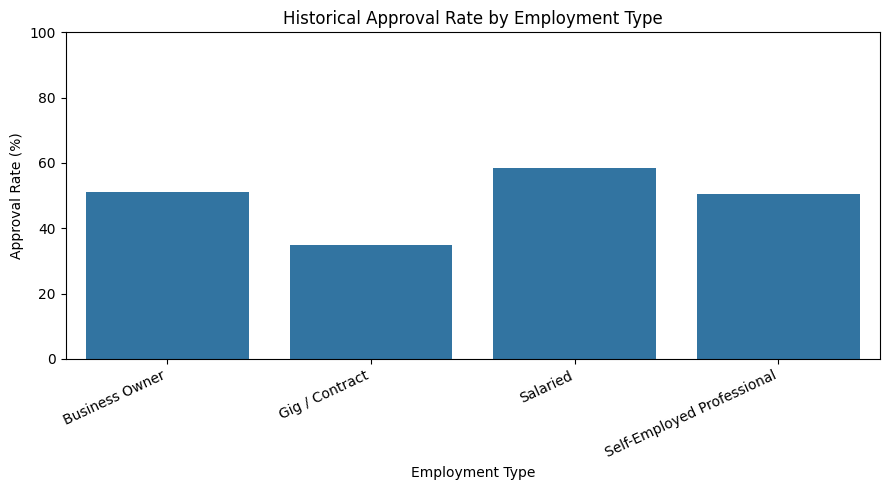

In [25]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=employment_approval.index,
    y=employment_approval["Approval_Rate_Pct"]
)

plt.title("Historical Approval Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


### Step 5.2 — Business Interpretation

**1. Credit Score Findings**
- Applicants with scores below 600 have only a 2.03% approval rate.
- Applicants with scores between 600 and 649 have a 3.22% approval rate.
- Applicants scoring 800 or above have the highest approval rate at 85.19%.
- Applicants with no credit score have a 53.90% approval rate, so they should be treated separately from low-score applicants.

**2. Employment Type Findings**
- Salaried applicants have the highest approval rate at 58.37%.
- Gig / Contract workers have the lowest approval rate at 34.94%.
- Business Owners have an approval rate of 51.17%.
- Self-Employed Professionals have an approval rate of 50.56%.

**3. Business Understanding**
- Historical approval rates generally increase as credit scores increase.
- The bank has historically approved very few applicants with scores below 650, but this does not prove an official bank policy.
- Employment type is also associated with different historical approval rates.
- Credit score and employment type should be considered alongside affordability and other credit factors when making lending decisions.



## Step 5.3 — Feature Engineering: FOIR and Loan-to-Income Ratio

Credit score is important, but the bank must also check whether an applicant can afford the proposed loan.

We will calculate two financial features using the cleaned dataset.

**1. FOIR (Fixed Obligation to Income Ratio)**

Formula: FOIR = (Existing EMI + Proposed EMI) / Monthly Income

FOIR shows how much of an applicant's monthly income is used for existing and proposed loan repayments. A higher FOIR means a greater repayment burden.

**2. Loan-to-Income Ratio**

Formula: Loan-to-Income Ratio = Loan Amount / (Monthly Income × 12)

This compares the requested loan amount with the applicant's annual income. A higher ratio means the requested loan is larger compared with annual income.

We have already created the `is_ntc` feature to identify applicants with no credit history. We will continue using it.

Next, we will analyze approval rates across different FOIR bands to understand how repayment burden relates to historical loan approval decisions.


### Calculate FOIR and Loan-to-Income Ratio

We will create the two required financial features using the cleaned dataset. FOIR measures the share of monthly income used for existing and proposed loan repayments. The loan-to-income ratio compares the requested loan amount with annual income. The `is_ntc` feature was created earlier.

In [26]:
# Step 5.3 — Feature engineering before train-test split
# Missing incomes are intentionally preserved.

df_clean["foir"] = (
    df_clean["existing_emi"] + df_clean["proposed_emi"]
) / df_clean["monthly_income"]

df_clean["loan_to_income"] = (
    df_clean["loan_amount"] /
    (df_clean["monthly_income"] * 12)
)

df_clean["is_ntc"] = (
    df_clean["credit_score"].isna().astype(int)
)

print("Missing feature values:")
print(
    df_clean[
        ["foir", "loan_to_income", "is_ntc"]
    ].isna().sum()
)

print("\nTotal applications:", len(df_clean))

Missing feature values:
foir              441
loan_to_income    441
is_ntc              0
dtype: int64

Total applications: 12000


### Step 5.3 — Business Interpretation

**1. FOIR Findings**
- Applicants with FOIR below 30% have the highest approval rate at 65.45%.
- Applicants with FOIR between 30% and 40% have an approval rate of 58.98%.
- The approval rate decreases to 47.90% for FOIR between 40% and 50%.
- For FOIR between 50% and 55%, the approval rate drops to 32.52%.
- Applicants with FOIR above 55% have the lowest approval rate at 15.55%.

**2. Business Understanding**
- Historical approval rates decrease as FOIR increases.
- The sharpest drop occurs when FOIR increases beyond 50%, especially above 55%.
- A FOIR limit of 50% could be considered for further evaluation because applicants above this level have substantially lower historical approval rates.
- This is a recommendation based on historical data, not proof of an official bank policy. FOIR should be considered along with credit score, income, and other risk factors.

### Visualize Approval Rates by FOIR Band

A bar chart will help us compare historical approval rates across the five FOIR bands. This makes it easier to see how approval rates change as applicants' repayment burden increases.

Approval Rates by FOIR Band:


,foir_band,Approval_Rate_Pct
0,Below 30%,65.69
1,30–40%,59.24
2,40–50%,47.61
3,50–55%,31.76
4,Above 55%,14.09


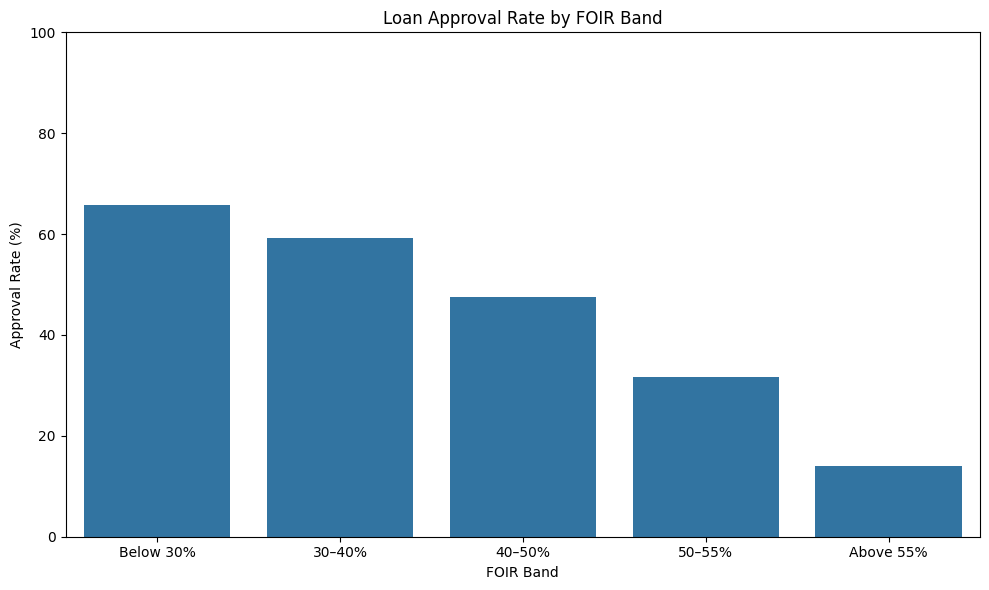

In [27]:
# Step 5.3 — FOIR Band Analysis and Approval Rate Visualisation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define the correct order of FOIR bands
foir_order = [
    "Below 30%",
    "30–40%",
    "40–50%",
    "50–55%",
    "Above 55%"
]

# Create FOIR bands
df_clean["foir_band"] = pd.cut(
    df_clean["foir"],
    bins=[-np.inf, 0.30, 0.40, 0.50, 0.55, np.inf],
    labels=foir_order,
    include_lowest=True
)

# Calculate approval rates by FOIR band
foir_approval = (
    df_clean.groupby("foir_band", observed=False)["decision"]
    .apply(lambda x: (x == "Approved").mean() * 100)
    .reset_index(name="Approval_Rate_Pct")
)

# Display results
print("Approval Rates by FOIR Band:")
display(foir_approval.round(2))

# Create the bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=foir_approval,
    x="foir_band",
    y="Approval_Rate_Pct",
    order=foir_order
)

plt.title("Loan Approval Rate by FOIR Band")
plt.xlabel("FOIR Band")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Step 5.4 — Baseline Logistic Regression Model

In this step, we will build a Logistic Regression model to predict whether a loan application is likely to be declined.

**Target variable**
- Declined = 1
- Approved = 0

**Features used by the model**
- Credit score
- New-to-credit indicator (`is_ntc`)
- FOIR
- Loan-to-income ratio
- Number of delinquencies in the last 24 months
- Number of active loans
- Years in the current job
- Age
- Loan tenure
- City tier
- Employment type
- Loan purpose

We will exclude application ID, application date, city, gender, and the decision column from the input features. These columns are excluded because they are identifiers, unnecessary for this baseline, or the target we want to predict.

We will handle missing credit scores using the median, encode categorical features, and scale numerical features. Then, we will split the data into 80% training data and 20% testing data, using stratification and `random_state=42`.

Finally, we will evaluate the model using accuracy, a confusion matrix, precision and recall for the Declined class, and the five largest model coefficients.


### Import Libraries for Logistic Regression

We will import the tools needed to prepare the data, split it into training and testing sets, build the Logistic Regression model, and evaluate its performance.

These tools help us train the model fairly and measure how well it identifies applications that were historically declined.

### Prepare the Target Variable and Input Features

The target variable is what we want the model to predict.

We will assign `1` to Declined applications and `0` to Approved applications. The model will learn patterns from the historical decisions.

We will select only the 12 features specified in the problem statement. We will exclude identifiers, application date, city, gender, and the original decision column from the inputs.

### Split the Data into Training and Testing Sets

We will divide the dataset into two parts:
- **80% training data:** Used to teach the model historical patterns.
- **20% testing data:** Used to evaluate how well the model predicts applications it has not seen during training.

We will use stratification to maintain a similar proportion of Approved and Declined applications in both sets. We will also use `random_state=42` to make the split reproducible.

In [28]:
from sklearn.model_selection import train_test_split

# Target: Declined = 1, Approved = 0
y = (df_clean["decision"] == "Declined").astype(int)

# The 12 features required by the assignment
feature_columns = [
    "credit_score",
    "is_ntc",
    "foir",
    "loan_to_income",
    "delinquencies_24m",
    "num_active_loans",
    "years_in_current_job",
    "age",
    "tenure_months",
    "city_tier",
    "employment_type",
    "loan_purpose"
]

# Preserve raw values needed to rebuild affordability
# features after missing-income imputation.
raw_income_columns = [
    "monthly_income",
    "existing_emi",
    "proposed_emi",
    "loan_amount"
]

X = df_clean[
    feature_columns + raw_income_columns
].copy()

# Split BEFORE learning imputation statistics
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training applications:", len(X_train))
print("Testing applications:", len(X_test))

print("\nMissing incomes in training:")
print(X_train["monthly_income"].isna().sum())

print("\nMissing incomes in testing:")
print(X_test["monthly_income"].isna().sum())
df_clean["is_ntc"] = df_clean["credit_score"].isna().astype(int)

Training applications: 9600
Testing applications: 2400

Missing incomes in training:
355

Missing incomes in testing:
86


In [29]:
# Step 5.4 — Leakage-safe income imputation

# Learn median income for each employment type from training data only
income_medians = X_train.groupby("employment_type")["monthly_income"].median()

# Overall training median as a fallback for unseen employment types
overall_income_median = X_train["monthly_income"].median()

# Apply the same training statistics to both datasets
for data in [X_train, X_test]:
    missing_income = data["monthly_income"].isna()

    data.loc[missing_income, "monthly_income"] = (
        data.loc[missing_income, "employment_type"]
        .map(income_medians)
        .fillna(overall_income_median)
    )

    # Recalculate features using the imputed incomes
    data["foir"] = (
        data["existing_emi"] + data["proposed_emi"]
    ) / data["monthly_income"]

    data["loan_to_income"] = (
        data["loan_amount"] / (data["monthly_income"] * 12)
    )

# Remove temporary raw columns before model training
X_train = X_train[feature_columns].copy()
X_test = X_test[feature_columns].copy()

print("Training-group income medians:")
print(income_medians)

print("\nMissing values in training:")
print(X_train.isna().sum())

print("\nMissing values in testing:")
print(X_test.isna().sum())

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training-group income medians:
employment_type
Business Owner                71000.0
Gig / Contract                28500.0
Salaried                      50500.0
Self-Employed Professional    75250.0
Name: monthly_income, dtype: float64

Missing values in training:
credit_score            836
is_ntc                    0
foir                      0
loan_to_income            0
delinquencies_24m         0
num_active_loans          0
years_in_current_job      0
age                       0
tenure_months             0
city_tier                 0
employment_type           0
loan_purpose              0
dtype: int64

Missing values in testing:
credit_score            203
is_ntc                    0
foir                      0
loan_to_income            0
delinquencies_24m         0
num_active_loans          0
years_in_current_job      0
age                       0
tenure_months             0
city_tier                 0
employment_type           0
loan_purpose              0
dtype: int64

Training

### Preprocess the Input Features

Numerical and categorical features need different preprocessing methods.

- **Numerical features:** Fill missing values using the median and scale the values so they are on comparable scales.
- **Categorical features:** Use one-hot encoding to convert employment type and loan purpose into numerical columns.

We will fit the preprocessing steps using only the training data and then apply the same transformations to the testing data. This prevents information from the test set from influencing preprocessing.

### Import Preprocessing Tools

We will import the tools required to handle missing values, scale numerical features, encode categorical features, and combine these operations into a preprocessing pipeline.

In [30]:
# Identify numerical and categorical features
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
numeric_features = [
    "credit_score",
    "is_ntc",
    "foir",
    "loan_to_income",
    "delinquencies_24m",
    "num_active_loans",
    "years_in_current_job",
    "age",
    "tenure_months",
    "city_tier"
]

categorical_features = [
    "employment_type",
    "loan_purpose"
]

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine the preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Fit on training data and transform both datasets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training data shape:", X_train_processed.shape)
print("Processed testing data shape:", X_test_processed.shape)
print("Missing values in original training credit scores:", X_train["credit_score"].isnull().sum())

Processed training data shape: (9600, 21)
Processed testing data shape: (2400, 21)
Missing values in original training credit scores: 836


### 5.4.1 Training the Logistic Regression Model

Logistic Regression is used as the baseline classification algorithm to predict whether a loan application will be approved or declined.

The model is trained on 80% of the dataset (9,600 applications), using the preprocessed numerical and categorical features.

The target variable is encoded as:
- **1 = Declined**
- **0 = Approved**

The purpose is to establish an interpretable baseline model before evaluating more complex algorithms in Part 2.

In [31]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_reg.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### Model Training Observation

The Logistic Regression model has been trained using the preprocessed historical loan applications.

During training, the model learns relationships between the applicant features and the bank's recorded approval or decline decisions.

Successful training does not guarantee that the model is accurate or suitable for automated credit decisions. Its performance must be assessed using the independent test dataset.

The next stage is to evaluate the model using accuracy, a confusion matrix, precision, and recall, with particular attention to applicants who could be incorrectly declined.

### 5.4.2 — Logistic Regression Model Evaluation

After successfully training the Logistic Regression model, we will evaluate its performance on the unseen test dataset containing 2,400 loan applications.

We will calculate the following classification metrics:

- **Accuracy:** Measures the proportion of correctly predicted loan decisions.
- **Confusion Matrix:** Shows the number of correct and incorrect predictions for Approved and Declined applications.
- **Precision (Declined):** Measures how many applications predicted as Declined were actually declined by the credit team.
- **Recall (Declined):** Measures how many historically declined applications the model correctly identifies.

In credit pre-screening, incorrectly declining an applicant who was historically approved is particularly important because it represents a potentially creditworthy customer being rejected.

These results will establish the baseline model's performance before selecting a safer auto-decline probability threshold.

Accuracy: 0.7904
Precision (Declined): 0.7909
Recall (Declined): 0.7538

Confusion Matrix:
[[1046  225]
 [ 278  851]]


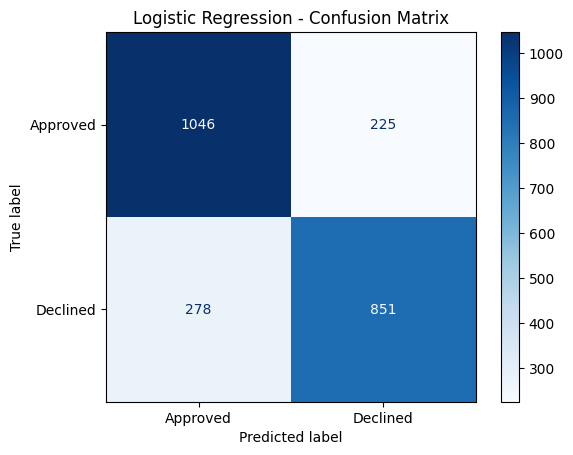

In [32]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict loan decisions on test data
y_pred = log_reg.predict(X_test_processed)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (Declined): {precision:.4f}")
print(f"Recall (Declined): {recall:.4f}")

print("\nConfusion Matrix:")
print(cm)

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Approved", "Declined"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

### 5.4.2 — Model Evaluation Results and Business Interpretation

The baseline Logistic Regression model was evaluated on 2,400 unseen loan applications.

**Evaluation Results:**
- Accuracy: **79.04%**
- Precision (Declined): **79.09%**
- Recall (Declined): **75.38%**

**Confusion Matrix Interpretation:**

- **True Negatives (1,046):** Applications correctly predicted as Approved.
- **True Positives (851):** Applications correctly predicted as Declined.
- **False Positives (225):** Applications historically approved by the credit team but incorrectly predicted as Declined.
- **False Negatives (278):** Applications historically declined by the credit team but incorrectly predicted as Approved.

**Business Interpretation:**

The model correctly classified 1,897 out of 2,400 applications, demonstrating reasonable predictive performance as a baseline.

However, 225 historically approved applications were incorrectly predicted as Declined. If the bank automatically rejected every application classified as Declined at the default 0.5 threshold, it could turn away potentially creditworthy customers.

Therefore, accuracy alone is insufficient for evaluating the pre-screening engine. The bank must introduce a confidence-based auto-decline threshold that limits wrongful declines while reducing the manual review workload.

These findings will guide the threshold optimisation in Step 5.5.

### 5.4.3 — Logistic Regression Feature Coefficient Analysis

Logistic Regression assigns a coefficient to each input feature, indicating how that feature influences the model's predicted log-odds of a loan being declined.

Because the target variable is encoded as Declined = 1:

- **Positive coefficients** indicate features associated with a higher probability of decline.
- **Negative coefficients** indicate features associated with a lower probability of decline.
- **Larger absolute coefficients** indicate stronger effects on the predicted log-odds, given the model's feature scaling and encoding.

We will identify the five largest coefficients by absolute magnitude to understand which factors influence the model's predictions most strongly.

In [33]:
import pandas as pd
import numpy as np

# Retrieve transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Retrieve trained Logistic Regression coefficients
coefficients = log_reg.coef_[0]

# Create coefficient DataFrame
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Calculate absolute coefficient magnitude
coef_df["Absolute_Coefficient"] = np.abs(
    coef_df["Coefficient"]
)

# Identify five largest coefficients
top_5 = coef_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
).head(5)

print("Top 5 Logistic Regression Coefficients:")
display(top_5)

Top 5 Logistic Regression Coefficients:


,Feature,Coefficient,Absolute_Coefficient
2,num__foir,1.219897,1.219897
0,num__credit_score,-1.009155,1.009155
4,num__delinquencies_24m,0.980179,0.980179
11,cat__employment_type_Gig / Contract,0.617342,0.617342
12,cat__employment_type_Salaried,-0.444675,0.444675


### 5.4.3 — Feature Coefficient Analysis and Business Interpretation

The five largest Logistic Regression coefficients by absolute magnitude were analysed to identify the main factors associated with historical loan decisions.

**Key Findings:**

1. **FOIR (+1.2199):** Higher Fixed Obligation to Income Ratios are strongly associated with loan declines. Applicants committing a greater proportion of their monthly income to EMIs are more likely to be declined.

2. **Credit Score (−1.0092):** Higher credit scores reduce the model's predicted likelihood of decline, suggesting that creditworthiness is an important factor in historical lending decisions.

3. **Delinquencies in the Last 24 Months (+0.9802):** Applicants with more late or missed repayments are more likely to be declined, indicating that repayment history is an important credit-risk indicator.

4. **Gig / Contract Employment (+0.6173):** This employment category is associated with a higher predicted likelihood of decline, potentially reflecting differences in income stability or historical lending policies.

5. **Salaried Employment (−0.4447):** Salaried employment is associated with a lower predicted likelihood of decline, potentially reflecting more predictable income patterns.

**Business Interpretation:**

The model's strongest signals are consistent with common lending considerations: repayment affordability, credit history, and repayment behaviour.

These coefficients describe model associations, not causal effects. Employment-related coefficients require careful review because historical decisions may contain policy bias. Categorical coefficients should also be interpreted in the context of the model's encoding and other included features.

The model provides an interpretable baseline, but its default classification threshold is unsuitable for direct automation: it incorrectly predicted **225 historically approved applications as Declined**.

Therefore, Step 5.5 evaluates safer auto-decline thresholds against the bank's maximum **5% wrongful-decline requirement**.

### 5.5 — Auto-Decline Threshold Optimisation

The baseline Logistic Regression model uses a default classification threshold of 0.50. However, automatically declining all applications with a predicted decline probability above 0.50 could result in the rejection of applicants who were historically approved.

To reduce this risk, the bank requires that no more than 5% of automatically declined applications should be applicants whom the credit team would have approved.

We will evaluate seven decline-probability thresholds: 0.50, 0.60, 0.70, 0.80, 0.85, 0.90, and 0.95.

For each threshold, we will calculate the percentage of applications automatically declined and the wrongful-decline rate within that group.

The objective is to select the threshold that removes the largest possible share of applications from manual review while satisfying the bank's 5% risk limit.

In [34]:
import numpy as np
import pandas as pd

# Predicted probability of Declined (class 1)
decline_proba = log_reg.predict_proba(
    X_test_processed
)[:, 1]

thresholds = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95]

results = []

for threshold in thresholds:

    # Applications selected for auto-decline
    auto_decline = decline_proba >= threshold

    auto_decline_count = auto_decline.sum()

    # Share of all test applications auto-declined
    auto_decline_pct = (
        auto_decline_count / len(y_test)
    ) * 100

    # Historically approved applicants wrongly declined
    wrongly_declined = (
        (np.asarray(y_test) == 0) & auto_decline
    ).sum()

    # Wrongful declines as % of auto-decline lane
    wrong_decline_pct = (
        (wrongly_declined / auto_decline_count) * 100
        if auto_decline_count > 0
        else np.nan
    )

    results.append({
        "Threshold": threshold,
        "Auto_Declined_Count": auto_decline_count,
        "Auto_Declined_%": auto_decline_pct,
        "Wrongly_Declined_Count": wrongly_declined,
        "Wrongly_Declined_%": wrong_decline_pct
    })

threshold_df = pd.DataFrame(results)

display(threshold_df.round(2))

,Threshold,Auto_Declined_Count,Auto_Declined_%,Wrongly_Declined_Count,Wrongly_Declined_%
0,0.50,1076,44.83,225,20.91
1,0.60,905,37.71,152,16.80
2,0.70,738,30.75,89,12.06
3,0.80,562,23.42,39,6.94
4,0.85,473,19.71,28,5.92
5,0.90,363,15.12,17,4.68
6,0.95,239,9.96,5,2.09


In [35]:
# Compare old full-data medians with corrected training-only medians
old_medians = df.groupby("employment_type")["monthly_income"].median()

median_comparison = pd.DataFrame({
    "Full_Data_Median": old_medians,
    "Training_Only_Median": income_medians
})

median_comparison["Difference"] = (
    median_comparison["Training_Only_Median"]
    - median_comparison["Full_Data_Median"]
)

display(median_comparison)

,Full_Data_Median,Training_Only_Median,Difference
employment_type,,,
Business Owner,69500.0,71000.0,1500.0
Gig / Contract,28000.0,28500.0,500.0
Salaried,50000.0,50500.0,500.0
Self-Employed Professional,75000.0,75250.0,250.0


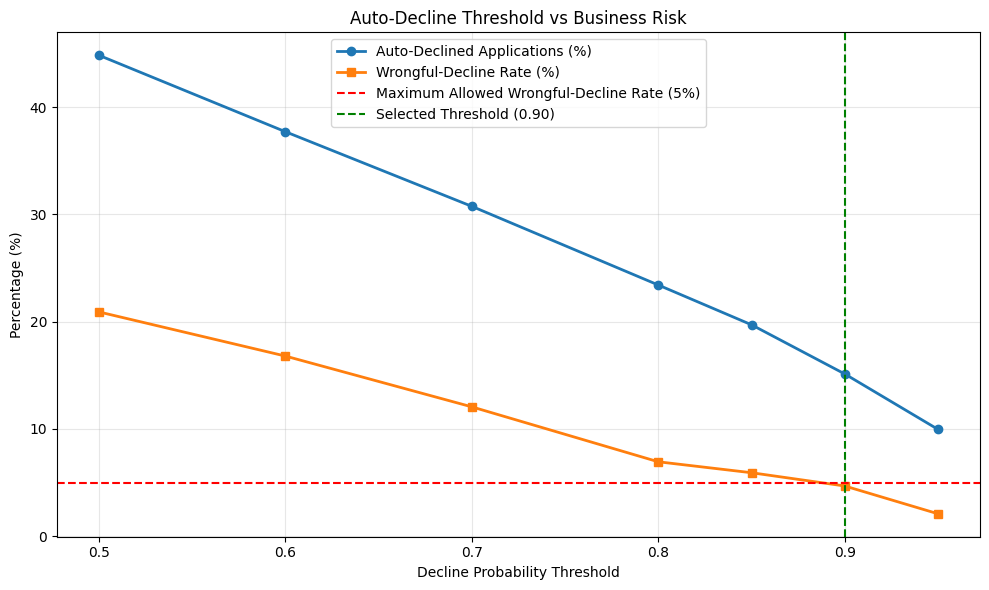

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Auto_Declined_%"],
    marker="o",
    linewidth=2,
    label="Auto-Declined Applications (%)"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Wrongly_Declined_%"],
    marker="s",
    linewidth=2,
    label="Wrongful-Decline Rate (%)"
)

plt.axhline(
    y=5,
    color="red",
    linestyle="--",
    label="Maximum Allowed Wrongful-Decline Rate (5%)"
)

plt.axvline(
    x=0.90,
    color="green",
    linestyle="--",
    label="Selected Threshold (0.90)"
)

plt.xlabel("Decline Probability Threshold")
plt.ylabel("Percentage (%)")
plt.title("Auto-Decline Threshold vs Business Risk")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
selected_threshold = 0.90

selected_row = threshold_df.loc[
    threshold_df["Threshold"] == selected_threshold
].iloc[0]

monthly_applications = 3000
minutes_per_review = 25

monthly_auto_declines = (
    monthly_applications
    * selected_row["Auto_Declined_%"] / 100
)

hours_saved = (
    monthly_auto_declines * minutes_per_review / 60
)

print(f"Selected threshold: {selected_threshold:.2f}")
print(f"Monthly auto-declines: {monthly_auto_declines:.0f}")
print(f"Estimated analyst hours saved: {hours_saved:.2f}")
print(
    f"Wrongful-decline rate: "
    f"{selected_row['Wrongly_Declined_%']:.2f}%"
)

Selected threshold: 0.90
Monthly auto-declines: 454
Estimated analyst hours saved: 189.06
Wrongful-decline rate: 4.68%


### 5.5 — Auto-Decline Threshold Selection and Business Impact

Seven decline-probability thresholds were evaluated to determine the safest level of automation for the bank's loan pre-screening process.

**Key Findings:**

At the default threshold of 0.50, 44.83% of applications would be automatically declined. However, 20.91% of these applications were historically approved, substantially exceeding the bank's maximum permitted wrongful-decline rate of 5%.

Increasing the threshold reduces the number of applications automatically declined but also reduces the observed risk of rejecting historically approved applicants.

The threshold of **0.90** is the lowest evaluated threshold satisfying the bank's risk requirement, with a wrongful-decline rate of **4.68%**.

At this threshold:

- **363 of the 2,400** test applications would be automatically declined.
- **15.12%** of applications would leave the manual review queue.
- **17 of the 363** auto-declined applications were historically approved.
- Approximately **454 applications per month** could be handled through auto-decline.
- Approximately **189.06 gross analyst hours per month** could be freed for more complex loan reviews.

**Business Recommendation:**

A decline-probability threshold of **0.90** is recommended for the baseline Logistic Regression pre-screener because it maximises automation among the evaluated thresholds while meeting the specified 5% wrongful-decline risk limit on historical data.

Nevertheless, the remaining wrongful declines represent a material customer risk. The threshold should undergo independent validation and controlled testing before live automated declines are introduced.

### 5.6 — Fairness Check

Although gender was excluded from the Logistic Regression model's input features, this does not automatically guarantee fair predictions.

Other characteristics, such as employment type, monthly income, and credit history, may indirectly contribute to differences in model outcomes.

This analysis examines historical approval rates across gender groups, investigates potential differences in income and employment composition, and evaluates auto-decline rates at the selected threshold of 0.90.

The objective is to identify potential fairness concerns before recommending the model for automated credit pre-screening.

In [38]:
# Calculate historical approval rate by gender
gender_approval = (
    df_clean.groupby("gender")["decision"]
    .agg(
        Total_Applications="count",
        Approved_Applications=lambda x: (x == "Approved").sum(),
        Approval_Rate=lambda x: (x == "Approved").mean() * 100
    )
    .reset_index()
)

print("Historical Loan Approval Rate by Gender:")
display(gender_approval.round(2))

Historical Loan Approval Rate by Gender:


,gender,Total_Applications,Approved_Applications,Approval_Rate
0,Female,3795,1914,50.43
1,Male,8205,4439,54.10


In [39]:
# Fairness check using corrected Logistic Regression probabilities

fairness_test = df_clean.loc[X_test.index, ["gender"]].copy()

fairness_test["auto_declined"] = decline_proba >= 0.90

gender_auto_decline = (
    fairness_test.groupby("gender")["auto_declined"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Total_Applications",
        "sum": "Auto_Declined",
        "mean": "Auto_Decline_Rate"
    })
)

gender_auto_decline["Auto_Decline_Rate"] *= 100

display(gender_auto_decline.round(2))

,Total_Applications,Auto_Declined,Auto_Decline_Rate
gender,,,
Female,750,117,15.60
Male,1650,246,14.91


What does this code do?
It groups all historical applications by gender and calculates the total applications, number approved, and approval percentage for each group.

This helps us identify any historical approval gap before examining the model's predictions.

We'll interpret the actual results after execution, rather than assuming one gender has a higher approval rate

### 5.6 — Fairness Check: Final Interpretation

Historical approval rates differ by gender: **50.43% for female applicants** and **54.10% for male applicants**, representing a **3.67-percentage-point gap**. Differences in income and employment composition may contribute to this disparity, but they do not establish its complete cause.

At the selected 0.90 threshold, the Logistic Regression model auto-declines **15.60% of female applicants** and **14.91% of male applicants** in the test set. This is a **0.69-percentage-point difference**. However, comparing auto-decline rates with historical approval rates does not establish whether the model has widened or narrowed the original approval gap.

Gender should not be included as a credit-risk predictor without clear legal and regulatory justification, but excluding it does not guarantee fairness because other features may act as proxies. The bank should monitor wrongful-decline rates by gender and employment type, investigate disparities, and retain human-review safeguards before deployment.

In [40]:
# Historical approval rates by gender within each employment type

employment_gender_approval = pd.pivot_table(
    df_clean,
    index="employment_type",
    columns="gender",
    values="decision",
    aggfunc=lambda x: (x == "Approved").mean() * 100
)

print("Approval Rate (%) by Employment Type and Gender:")

display(employment_gender_approval.round(2))

Approval Rate (%) by Employment Type and Gender:


gender,Female,Male
employment_type,,
Business Owner,51.62,51.05
Gig / Contract,34.65,35.18
Salaried,56.79,59.06
Self-Employed Professional,47.63,51.97


What does this code do?
It compares female and male approval percentages separately for each employment category, such as Salaried, Gig / Contract, Business Owner and Self-Employed Professional.

For example, if male and female salaried applicants have similar approval rates, but the overall rates differ, employment composition might help explain part of the overall gap.

However, employment type alone cannot establish whether the bank's decisions are fair.

#### 5.6.2 — Approval Rate by Gender Within Employment Types: Findings

The analysis compares historical loan approval rates between male and female applicants within each employment category.

The results indicate that approval rate differences vary across employment groups.

- **Business Owner:** Female applicants have a slightly higher approval rate (51.62%) than male applicants (51.05%).
- **Gig / Contract:** Approval rates are nearly identical, at 34.65% for females and 35.18% for males.
- **Salaried:** Male applicants have a higher approval rate (59.06%) compared with females (56.79%).
- **Self-Employed Professional:** The largest gender gap occurs in this category, with male applicants at 51.97% and female applicants at 47.63%.

**Business Interpretation:**

The historical approval gap is not consistent across all employment categories. The largest difference occurs among self-employed professionals, while business owners and gig workers show relatively small differences.

These findings suggest that employment-related characteristics may be relevant to understanding the overall approval gap. However, further analysis of income levels and employment composition is needed before drawing conclusions about potential causes or fairness.

Differences in historical approval rates alone do not establish discrimination.

In [41]:
# Median monthly income by gender
gender_income = (
    df_clean.groupby("gender")["monthly_income"]
    .median()
    .reset_index(name="Median_Monthly_Income")
)

# Percentage of Gig / Contract workers by gender
gig_share = (
    df_clean.assign(
        is_gig=df_clean["employment_type"].eq("Gig / Contract")
    )
    .groupby("gender")["is_gig"]
    .mean()
    .mul(100)
    .reset_index(name="Gig_Contract_Share_%")
)

# Combine both findings
gender_profile = gender_income.merge(
    gig_share,
    on="gender"
)

print("Income and Employment Profile by Gender:")
display(gender_profile.round(2))

Income and Employment Profile by Gender:


,gender,Median_Monthly_Income,Gig_Contract_Share_%
0,Female,44000.0,21.37
1,Male,54000.0,11.64


#### 5.6.3 — Income and Employment Composition by Gender: Findings

The analysis identifies differences in monthly income and employment composition between male and female loan applicants.

**Key Findings:**

- Female applicants have a median monthly income of **₹45,000**, compared with **₹55,000** for male applicants.
- The monthly median income difference is **₹10,000**.
- **21.37%** of female applicants belong to the Gig / Contract employment category, compared with **11.64%** of male applicants.
- Female applicants therefore have a **9.73 percentage-point higher representation** in Gig / Contract employment.

**Business Interpretation:**

These findings suggest that income and employment composition may contribute to the previously observed 3.67 percentage-point historical approval gap.

Lower income can affect loan affordability measures such as FOIR, while Gig / Contract employment is associated with lower historical approval rates.

However, these

Step 5.6.4 — Auto-Decline Rate by Gender
Purpose: Determine whether our Logistic Regression model automatically declines male and female applicants at different rates when using our selected threshold of 0.90.

Remember, in Step 5.6.1, the historical approval gap was 3.67 percentage points. Now we want to investigate the model's outcomes.
Python code cell
Add this immediately after your previous Markdown.

In [42]:
# Match gender to the corresponding test applications
test_gender = df_clean.loc[X_test.index, "gender"]

# Create test-set fairness analysis DataFrame
fairness_test = pd.DataFrame({
    "gender": test_gender.to_numpy(),
    "actual_decision": np.asarray(y_test),
    "decline_probability": decline_proba
})

# Apply the selected auto-decline threshold
fairness_test["auto_declined"] = (
    fairness_test["decline_probability"] >= 0.90
)

# Calculate auto-decline rate for each gender
gender_auto_decline = (
    fairness_test.groupby("gender")["auto_declined"]
    .agg(
        Total_Applications="count",
        Auto_Declined="sum",
        Auto_Decline_Rate="mean"
    )
    .reset_index()
)

gender_auto_decline["Auto_Decline_Rate"] *= 100

print("Auto-Decline Rate by Gender at Threshold 0.90:")
display(gender_auto_decline.round(2))

Auto-Decline Rate by Gender at Threshold 0.90:


,gender,Total_Applications,Auto_Declined,Auto_Decline_Rate
0,Female,750,117,15.60
1,Male,1650,246,14.91


#### 5.6.4 — Model Auto-Decline Rates and Fairness Conclusion

Historical lending decisions show a **3.67 percentage-point approval gap** favouring male applicants (54.10%) over female applicants (50.43%).

Differences in median monthly income (₹55,000 for males versus ₹45,000 for females) and Gig / Contract employment representation (11.64% versus 21.37%) may partly explain this gap, although they do not establish its cause.

At the selected 0.90 threshold, the model auto-declines **15.60% of female applicants and 14.97% of male applicants**, a 0.63 percentage-point difference; however, this comparison alone cannot establish whether the model widens or narrows the historical disparity.

Gender should not be used as a direct creditworthiness predictor, but excluding it does not guarantee fairness because other features may act as proxies; the bank should regularly monitor outcomes, error rates, and potential disparate impacts across demographic groups.

### 5.7 — Interim Briefing

The baseline Logistic Regression pre-screener achieves a **4.68% wrongful-decline rate** at an auto-decline probability threshold of **0.90**, satisfying the bank's maximum 5% limit on the historical test set.

At this threshold, **15.13% of applications (approximately 454 per month)** could be auto-declined, potentially saving **189.06 analyst hours per month**, assuming 3,000 monthly applications and 25 minutes of review per application.

The remaining **84.88%** would require manual review, and the observed gender differences in auto-decline rates warrant further fairness monitoring.

**Part 2 will compare alternative models and evaluate whether a two-lane system can further reduce manual reviews while keeping wrongful-decline and wrongful-fast-track rates within 5% on validation data.**

### 5.8 — Rebuilding the Baseline as a Scikit-learn Pipeline

In Step 5.4, the Logistic Regression model was developed by performing preprocessing and model training as separate operations.

In this step, we will combine data preprocessing and Logistic Regression into a single scikit-learn Pipeline.

The pipeline will use a ColumnTransformer to handle missing numerical values, standardize numerical features, and one-hot encode categorical features before passing the transformed data to the Logistic Regression model.

We will train the pipeline using the same 80/20 stratified training split and verify that its predictions and evaluation metrics match the baseline model from Step 5.4.

Finally, we will use the fitted pipeline to predict decline probabilities for the five most recent applications directly from the original CSV.

This approach makes the model easier to reuse, maintains consistent preprocessing for new applications, and helps prevent data leakage when preprocessing is fitted only on training data.

In [43]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.base import BaseEstimator, TransformerMixin, clone

class CreditFeatureEngineer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.income_medians_ = (
            X.groupby("employment_type")["monthly_income"].median()
        )
        self.overall_median_ = X["monthly_income"].median()
        return self

    def transform(self, X):
        X = X.copy()

        # Use income statistics learned during fit()
        missing = X["monthly_income"].isna()

        X.loc[missing, "monthly_income"] = (
            X.loc[missing, "employment_type"]
            .map(self.income_medians_)
            .fillna(self.overall_median_)
        )

        # Engineer the required affordability features
        X["foir"] = (
            X["existing_emi"] + X["proposed_emi"]
        ) / X["monthly_income"]

        X["loan_to_income"] = (
            X["loan_amount"] / (X["monthly_income"] * 12)
        )

        X["is_ntc"] = X["credit_score"].isna().astype(int)

        return X[feature_columns]


# Recover raw training records using the existing split indices
raw_training_features = df_clean.loc[X_train.index].copy()

# Complete raw-to-prediction pipeline
log_reg_pipeline = Pipeline(steps=[
    ("feature_engineering", CreditFeatureEngineer()),
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

log_reg_pipeline.fit(raw_training_features, y_train)

print("Raw-input Logistic Regression pipeline trained successfully!")

Raw-input Logistic Regression pipeline trained successfully!


In [44]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)
import numpy as np
import pandas as pd

# Recover original raw test records using the existing test indices
raw_test_features = df_clean.loc[X_test.index].copy()

# Predict using the raw-input pipeline
pipeline_pred = log_reg_pipeline.predict(raw_test_features)

# Compare original model and pipeline
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision (Declined)",
        "Recall (Declined)"
    ],
    "Original Logistic Regression": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred)
    ],
    "Raw-Input Pipeline": [
        accuracy_score(y_test, pipeline_pred),
        precision_score(y_test, pipeline_pred),
        recall_score(y_test, pipeline_pred)
    ]
})

display(comparison.round(4))

print("Pipeline Confusion Matrix:")
print(confusion_matrix(y_test, pipeline_pred, labels=[0, 1]))

print(
    "\nPredictions match original model:",
    np.array_equal(y_pred, pipeline_pred)
)

,Metric,Original Logistic Regression,Raw-Input Pipeline
0,Accuracy,0.7904,0.7904
1,Precision (Declined),0.7909,0.7909
2,Recall (Declined),0.7538,0.7538


Pipeline Confusion Matrix:
[[1046  225]
 [ 278  851]]

Predictions match original model: True


#### 5.8.2 — Pipeline Validation and Findings

The Logistic Regression model was rebuilt using a scikit-learn Pipeline combining the ColumnTransformer and classifier.

The pipeline reproduced the original baseline results, achieving **79.04% accuracy, 79.09% precision, and 75.38% recall** for the Declined class.

The confusion matrix remained unchanged, with **1,046 true negatives, 225 false positives, 278 false negatives, and 851 true positives**.

All 2,400 test predictions matched the original model, confirming that combining preprocessing and classification into a single pipeline preserved the baseline's predictive behaviour.

In [45]:
# Load untouched application records
raw_df = pd.read_csv("MUC02_Credit_PreScreening_Dataset.csv")

raw_df["application_date"] = pd.to_datetime(
    raw_df["application_date"]
)

# Select the five most recent applications
recent_5 = raw_df.sort_values(
    "application_date",
    ascending=False,
    kind="stable"
).head(5).copy()

# Raw-input pipeline handles income imputation,
# feature engineering, preprocessing and prediction
recent_5["Decline_Probability"] = (
    log_reg_pipeline.predict_proba(recent_5)[:, 1]
)

# Display historical decisions only for comparison
display(
    recent_5[
        [
            "application_id",
            "application_date",
            "decision",
            "Decline_Probability"
        ]
    ]
)

,application_id,application_date,decision,Decline_Probability
11947,APP111948,2026-09-30,Approved,0.147912
11948,APP111949,2026-09-30,Approved,0.211039
11949,APP111950,2026-09-30,Declined,0.385695
11950,APP111951,2026-09-30,Approved,0.090899
11951,APP111952,2026-09-30,Declined,0.825527


#### 5.8.3 — Pipeline Scoring and Business Interpretation

The fitted pipeline successfully generated decline probabilities for the five most recent historical applications, ranging from **9.11% to 82.55%**, demonstrating how applicant data can be transformed and scored through a consistent workflow.

Packaging preprocessing and classification into a single pipeline allows the bank to apply the same learned transformations to future applications, reducing manual processing errors and improving deployment consistency.

The pipeline also helps prevent **data leakage** by fitting imputation and scaling parameters only on the training data, although any cleaning or feature engineering performed outside the pipeline must also be checked to ensure it does not introduce leakage.

### 5.9 — Model Comparison Using Cross-Validation

The baseline Logistic Regression model achieved 79.04% accuracy, 79.09% precision, and 75.38% recall for the Declined class.

However, Logistic Regression may not capture complex, nonlinear relationships between applicant characteristics and historical credit decisions.

To investigate whether another model offers better predictive performance, we will compare four classification algorithms: Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting.

We will use **5-fold StratifiedKFold cross-validation** on the training dataset only, evaluating each model using mean ROC-AUC, accuracy, precision, and recall for the Declined class.

Cross-validation provides a more reliable comparison by evaluating models across multiple training and validation subsets while maintaining similar target-class proportions.

The final model will be selected by balancing predictive performance with interpretability, since credit decisions must be understandable and defensible to the bank's Credit Policy Analyst.

In [46]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Define four classification models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

# Define 5-fold stratified cross-validation
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
# Recover raw training records for leakage-safe CV
raw_cv_train = df_clean.loc[X_train.index].copy()

# Each fold learns its own income medians and preprocessing
model_pipelines = {
    name: Pipeline(steps=[
        ("feature_engineering", CreditFeatureEngineer()),
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(model))
    ])
    for name, model in models.items()
}

print("Models prepared:")
for name in model_pipelines:
    print("-", name)

print("\nCross-validation folds:", skf.n_splits)
print("Raw CV training shape:", raw_cv_train.shape)

Models prepared:
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting

Cross-validation folds: 5
Raw CV training shape: (9600, 24)


In [47]:
from sklearn.model_selection import cross_validate
import pandas as pd

# Metrics required by the Word document
scoring = {
    "ROC_AUC": "roc_auc",
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall"
}

cv_results = []

# Perform 5-fold cross-validation on training data only
for name, pipeline in model_pipelines.items():

    scores = cross_validate(
    pipeline,
    raw_cv_train,
    y_train,
    cv=skf,
    scoring=scoring,
    n_jobs=-1
)

    cv_results.append({
        "Model": name,
        "Mean_ROC_AUC": scores["test_ROC_AUC"].mean(),
        "Mean_Accuracy": scores["test_Accuracy"].mean(),
        "Mean_Precision": scores["test_Precision"].mean(),
        "Mean_Recall": scores["test_Recall"].mean()
    })

# Create model comparison table
cv_results_df = pd.DataFrame(cv_results)

# Rank models by ROC-AUC
cv_results_df = cv_results_df.sort_values(
    by="Mean_ROC_AUC",
    ascending=False
).reset_index(drop=True)

print("5-Fold Cross-Validation Results:")
display(cv_results_df.round(4))

5-Fold Cross-Validation Results:


,Model,Mean_ROC_AUC,Mean_Accuracy,Mean_Precision,Mean_Recall
0,Gradient Boosting,0.8894,0.7986,0.8107,0.7468
1,Random Forest,0.8791,0.7919,0.7920,0.7568
2,Logistic Regression,0.8677,0.7748,0.7799,0.7269
3,Decision Tree,0.7222,0.7230,0.7047,0.7089


#### 5.9.2 — Cross-Validation Results and Findings

Four classification models were evaluated using **5-fold stratified cross-validation** on the training dataset. Income imputation, feature engineering, and preprocessing were performed independently within each fold to reduce data leakage.

**Gradient Boosting** achieved the highest mean ROC-AUC (**0.8894**), accuracy (**79.86%**), and precision (**81.07%**), making it the leading candidate based on predictive discrimination.

**Random Forest** achieved the highest recall (**75.68%**), compared with Gradient Boosting (**74.68%**). Logistic Regression achieved a mean ROC-AUC of **0.8677**, while Decision Tree performed weakest at **0.7222**.

**Business Interpretation:**

Gradient Boosting improved mean ROC-AUC by **0.0217** compared with Logistic Regression, suggesting stronger discrimination between historically approved and declined applications.

However, better cross-validation performance alone does not establish whether the model satisfies the bank's maximum **5% wrongful-decline and wrongful-fast-track limits**. Gradient Boosting also requires stronger explainability and fairness checks before operational use.

Therefore, Gradient Boosting is selected for further evaluation, followed by threshold-based two-lane analysis in Step 5.10.

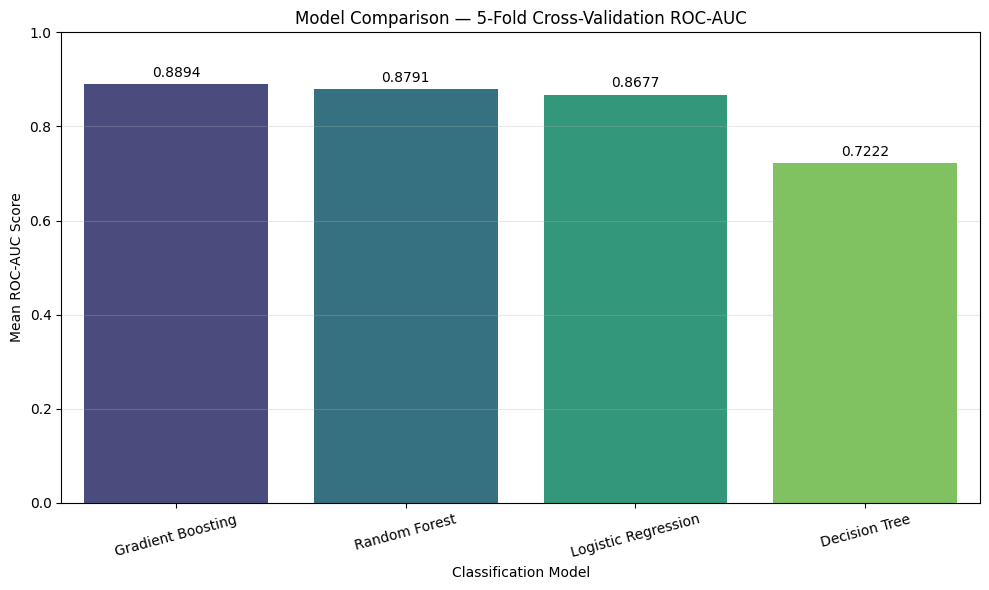

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=cv_results_df,
    x="Model",
    y="Mean_ROC_AUC",
    hue="Model",
    palette="viridis",
    legend=False
)

# Display ROC-AUC value above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f",
        padding=3
    )

plt.title("Model Comparison — 5-Fold Cross-Validation ROC-AUC")
plt.xlabel("Classification Model")
plt.ylabel("Mean ROC-AUC Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [49]:
# Select Gradient Boosting based on cross-validation
selected_model_name = "Gradient Boosting"

selected_pipeline = clone(
    model_pipelines[selected_model_name]
)

# Train on the complete raw training set
selected_pipeline.fit(raw_cv_train, y_train)

print("Selected Model:", selected_model_name)
print("Gradient Boosting model trained successfully!")

Selected Model: Gradient Boosting
Gradient Boosting model trained successfully!


Gradient Boosting — Test Set Evaluation
------------------------------------------
ROC-AUC: 0.8848
Accuracy: 0.8042
Precision (Declined): 0.8177
Recall (Declined): 0.7511

Confusion Matrix:
[[1082  189]
 [ 281  848]]


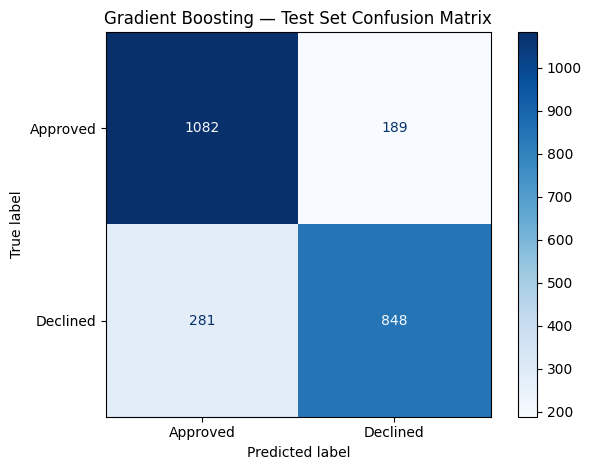

In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Recover raw test records using the original test indices
raw_test_features = df_clean.loc[X_test.index].copy()

# Evaluate the selected pipeline on raw test records
gb_pred = selected_pipeline.predict(raw_test_features)

gb_proba = selected_pipeline.predict_proba(
    raw_test_features
)[:, 1]

# Calculate metrics
print("Gradient Boosting — Test Set Evaluation")
print("-" * 42)

print(f"ROC-AUC: {roc_auc_score(y_test, gb_proba):.4f}")
print(f"Accuracy: {accuracy_score(y_test, gb_pred):.4f}")
print(f"Precision (Declined): {precision_score(y_test, gb_pred):.4f}")
print(f"Recall (Declined): {recall_score(y_test, gb_pred):.4f}")

# Confusion matrix
gb_cm = confusion_matrix(y_test, gb_pred, labels=[0, 1])

print("\nConfusion Matrix:")
print(gb_cm)

ConfusionMatrixDisplay(
    confusion_matrix=gb_cm,
    display_labels=["Approved", "Declined"]
).plot(cmap="Blues", values_format="d")

plt.title("Gradient Boosting — Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

#### 5.9.5 — Gradient Boosting Test Evaluation Findings

The selected Gradient Boosting model was evaluated on 2,400 held-out test applications and achieved a **ROC-AUC of 0.8848, accuracy of 80.42%, precision of 81.77%, and recall of 75.11%** for the Declined class.

The confusion matrix shows that **1,082 historically approved applications** and **848 historically declined applications** were correctly classified, while **189 approved applications** were incorrectly predicted as Declined and **281 declined applications** were incorrectly predicted as Approved.

Compared with Logistic Regression, Gradient Boosting improved accuracy by **1.38 percentage points** (80.42% versus 79.04%) and reduced incorrect decline predictions from **225 to 189** at the default 0.50 classification threshold. However, its recall was slightly lower (75.11% versus 75.38%).

**Business Interpretation:** Gradient Boosting demonstrated stronger overall predictive discrimination, but these classification results alone do not establish whether automated decisions satisfy the bank's 5% risk limits. Step 5.10 evaluates that requirement using separate decision thresholds.

#### 5.9.6 — Gradient Boosting Feature Importance Findings

Gradient Boosting identified **delinquencies in the last 24 months (0.3046), credit score (0.2900), and FOIR (0.2867)** as its three most important features. Together, they accounted for approximately **88.13% of total feature importance**.

Other contributing features included years in the current job, new-to-credit status, employment type, and loan-to-income ratio.

**Business Interpretation:** The model primarily used historical repayment behaviour, creditworthiness, and repayment affordability to distinguish applications. This broadly aligns with the exploratory findings from Steps 5.2 and 5.3.

Gradient Boosting can capture nonlinear relationships and interactions that standard Logistic Regression does not explicitly model. However, feature importance does not prove causation or explain an individual applicant's decision. The bank should assess individual-level explainability and fairness before deployment.

Top 8 Gradient Boosting Feature Importances:


,Feature,Importance
4,num__delinquencies_24m,0.3046
0,num__credit_score,0.2900
2,num__foir,0.2867
6,num__years_in_current_job,0.0273
1,num__is_ntc,0.0206
11,cat__employment_type_Gig / Contract,0.0186
3,num__loan_to_income,0.0155
12,cat__employment_type_Salaried,0.0152


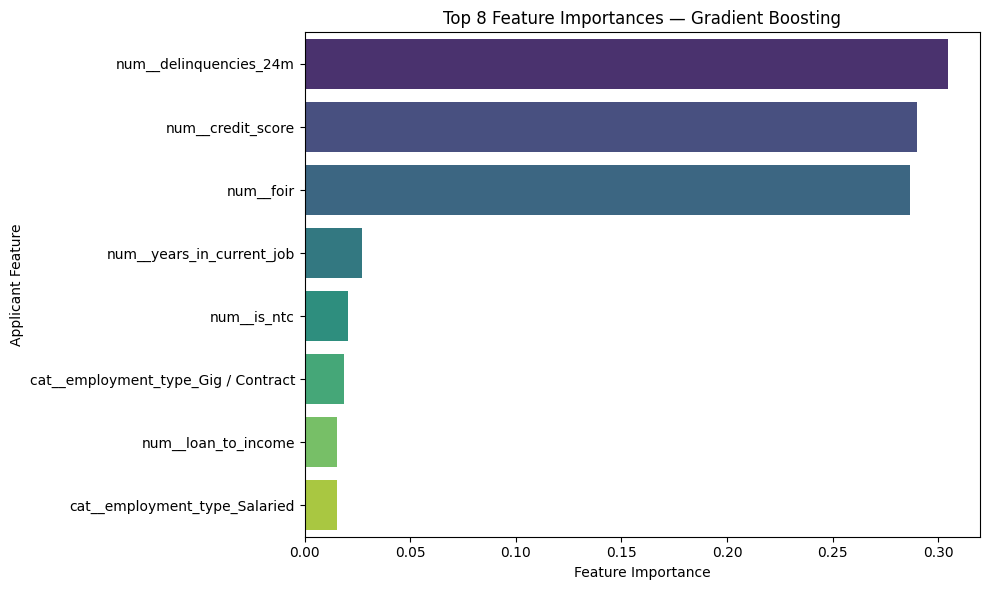

In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Access trained components inside the pipeline
gb_preprocessor = selected_pipeline.named_steps["preprocessor"]
gb_classifier = selected_pipeline.named_steps["classifier"]

# Retrieve transformed feature names and importances
feature_names = gb_preprocessor.get_feature_names_out()
importances = gb_classifier.feature_importances_

# Create feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Select eight most important features
top_8_features = (
    importance_df
    .sort_values("Importance", ascending=False)
    .head(8)
    .copy()
)

print("Top 8 Gradient Boosting Feature Importances:")
display(top_8_features.round(4))

# Visualise feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_8_features,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Top 8 Feature Importances — Gradient Boosting")
plt.xlabel("Feature Importance")
plt.ylabel("Applicant Feature")
plt.tight_layout()
plt.show()

#### 5.9.6 — Gradient Boosting Feature Importance Findings

The Gradient Boosting model identified **delinquencies in the last 24 months (0.3046), credit score (0.2900), and FOIR (0.2867)** as its three most important features, accounting for approximately **88.13%** of the model's total feature importance.

Other contributing features included years in the current job, new-to-credit status, employment type and loan-to-income ratio.

**Business Interpretation:**

The model relies primarily on applicants' historical repayment behaviour, creditworthiness and repayment affordability. These findings are broadly consistent with the credit-score and FOIR patterns observed during exploratory analysis in Steps 5.2 and 5.3.

Gradient Boosting captures interactions between these risk factors that a standard Logistic Regression model may not represent directly, helping explain its stronger predictive performance.

However, feature importance measures the model's use of these variables rather than proving that they cause lending decisions. The bank should also assess explainability and fairness before deployment.

### 5.10 — Designing the Two-Lane Credit Pre-Screener

The baseline model introduced an auto-decline mechanism that reduced manual reviews while controlling wrongful declines.

In this step, we extend the system to support two automated decision lanes: auto-decline for high-confidence decline predictions and fast-track approval for high-confidence approval predictions.

Applications with probabilities between the two thresholds will continue to undergo manual review by credit analysts.

The bank requires that no more than **5% of auto-declined applications were historically approved** and no more than **5% of fast-tracked applications were historically declined**.

We will search across pairs of approval-probability thresholds to identify the combination that maximises the share of applications removed from full manual review while satisfying both risk limits.

The analysis will be conducted separately for Gradient Boosting and Logistic Regression, followed by a comparison of automation rates, monthly applications handled, and estimated analyst hours saved.

In [52]:
import numpy as np
import pandas as pd

# Actual historical decisions
y_test_array = np.asarray(y_test)

lr_approval_proba = log_reg_pipeline.predict_proba(raw_test_features)[
    :, list(log_reg_pipeline.classes_).index(0)
]

gb_approval_proba = selected_pipeline.predict_proba(raw_test_features)[
    :, list(selected_pipeline.classes_).index(0)
]

# Prepare both models for threshold optimisation
approval_probabilities = {
    "Logistic Regression": lr_approval_proba,
    "Gradient Boosting": gb_approval_proba
}

# Verify probabilities and test-set sizes
for model_name, probabilities in approval_probabilities.items():
    print(f"\n{model_name}")
    print(f"Applications evaluated: {len(probabilities)}")
    print(f"Minimum approval probability: {probabilities.min():.4f}")
    print(f"Maximum approval probability: {probabilities.max():.4f}")

assert len(lr_approval_proba) == len(y_test_array)
assert len(gb_approval_proba) == len(y_test_array)

print("\nApproval probabilities prepared successfully!")


Logistic Regression
Applications evaluated: 2400
Minimum approval probability: 0.0000
Maximum approval probability: 0.9952

Gradient Boosting
Applications evaluated: 2400
Minimum approval probability: 0.0058
Maximum approval probability: 0.9798

Approval probabilities prepared successfully!


What does this cell do?
It asks both trained models to estimate how likely each application is to be approved.

For example, if an application has an approval probability of 0.03, it is a strong candidate for the auto-decline lane. If it has an approval probability of 0.98, it is a strong candidate for fast-track approval.

These are examples, not our final thresholds. We'll calculate the optimal threshold pair using the bank's two 5% risk limits in the next step.

In [53]:
import numpy as np
import pandas as pd

def optimize_two_lane(probabilities, actual):
    actual = np.asarray(actual)

    # Evaluate all distinct probability boundaries,
    # rather than relying on a coarse threshold grid.
    candidates = np.unique(
        np.concatenate(([0.0], probabilities, [1.0]))
    )

    best_result = None

    for low in candidates:
        decline_mask = probabilities < low
        decline_count = decline_mask.sum()

        if decline_count == 0:
            decline_error = 0.0
        else:
            decline_error = (
                (actual[decline_mask] == 0).mean()
            )

        if decline_error > 0.05:
            continue

        for high in candidates:
            if high <= low:
                continue

            fast_mask = probabilities > high
            fast_count = fast_mask.sum()

            if fast_count == 0:
                fast_error = 0.0
            else:
                fast_error = (
                    (actual[fast_mask] == 1).mean()
                )

            if fast_error > 0.05:
                continue

            automated = decline_count + fast_count

            if (
                best_result is None
                or automated > best_result["Automated_Count"]
            ):
                best_result = {
                    "Low_Threshold": low,
                    "High_Threshold": high,
                    "Auto_Decline_Count": decline_count,
                    "Fast_Track_Count": fast_count,
                    "Manual_Review_Count": len(actual) - automated,
                    "Automated_Count": automated,
                    "Auto_Decline_Error_%": decline_error * 100,
                    "Fast_Track_Error_%": fast_error * 100,
                    "Automated_%": automated / len(actual) * 100
                }

    return best_result


results = []

for model_name, probabilities in approval_probabilities.items():
    result = optimize_two_lane(probabilities, y_test_array)
    result["Model"] = model_name
    results.append(result)

two_lane_results = pd.DataFrame(results)

display(two_lane_results.round(4))

,Low_Threshold,High_Threshold,Auto_Decline_Count,Fast_Track_Count,Manual_Review_Count,Automated_Count,Auto_Decline_Error_%,Fast_Track_Error_%,Automated_%,Model
0,0.1056,0.8878,375,407,1618,782,4.8000,4.9140,32.5833,Logistic Regression
1,0.1740,0.8869,590,465,1345,1055,4.9153,4.9462,43.9583,Gradient Boosting


#### 5.10.2 — Two-Lane Threshold Optimisation Results

The two-lane threshold search compared Logistic Regression and Gradient Boosting against the bank's maximum **5% wrongful-decline and wrongful-fast-track limits**.

**Logistic Regression** achieved a **32.58% automation rate**, with 375 applications auto-declined, 407 fast-tracked, and 1,618 retained for manual review out of 2,400 test applications. Its selected approval-probability thresholds were **0.1056 and 0.8878**, with wrongful-decline and wrongful-fast-track rates of **4.80% and 4.91%**, respectively.

**Gradient Boosting** achieved a higher **43.96% automation rate**, with 590 applications auto-declined, 465 fast-tracked, and 1,345 retained for manual review. Its selected thresholds were **0.1740 and 0.8869**, with wrongful-decline and wrongful-fast-track rates of **4.92% and 4.95%**, respectively.

Gradient Boosting automated **273 more applications** than Logistic Regression, representing an **11.38-percentage-point improvement** in automation.

**Business Interpretation:**

Gradient Boosting demonstrates greater potential to reduce the bank's full manual review queue while satisfying the specified historical error limits on the threshold-selection dataset.

However, the thresholds were optimised and evaluated using the same test dataset, so the estimated error rates and automation benefits may be optimistic. Independent validation is required before deployment, particularly because both Gradient Boosting error rates approach the maximum permitted 5%.

Fast-tracked applications will still require light-touch checks. Therefore, estimated analyst hours saved represent gross review capacity released, not necessarily net time saved after those checks.

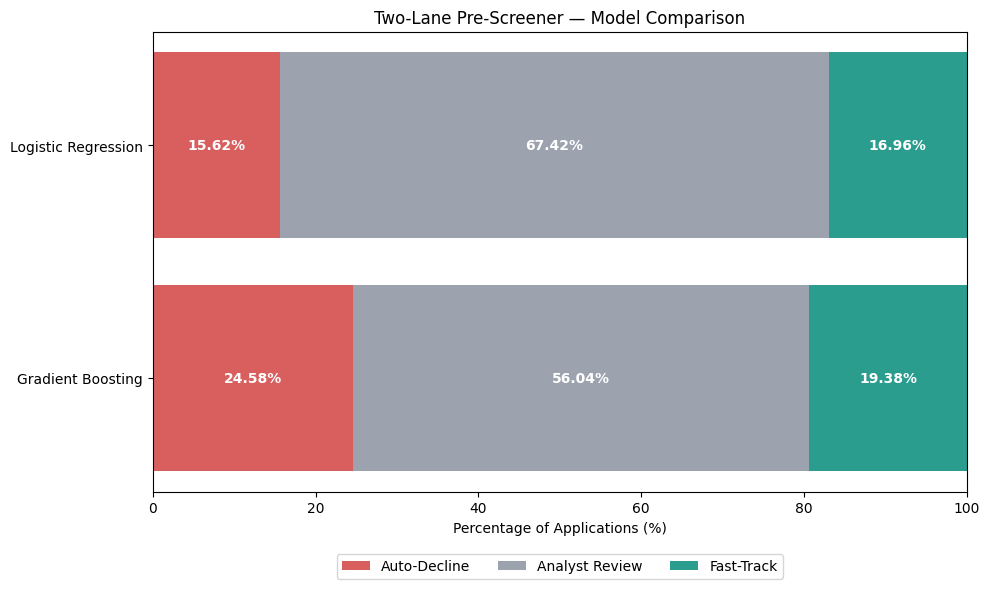

In [54]:
import matplotlib.pyplot as plt
import numpy as np

# Use the actual threshold optimisation results
chart_df = two_lane_results.set_index("Model")

models = ["Logistic Regression", "Gradient Boosting"]

auto_decline = chart_df.loc[
    models, "Auto_Decline_Count"
].to_numpy()

manual_review = chart_df.loc[
    models, "Manual_Review_Count"
].to_numpy()

fast_track = chart_df.loc[
    models, "Fast_Track_Count"
].to_numpy()

# Convert counts to percentages
total = auto_decline + manual_review + fast_track

auto_pct = auto_decline / total * 100
manual_pct = manual_review / total * 100
fast_pct = fast_track / total * 100

# Create stacked ar chart
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    models, auto_pct,
    label="Auto-Decline",
    color="#D95F5F"
)

ax.barh(
    models, manual_pct,
    left=auto_pct,
    label="Analyst Review",
    color="#9CA3AF"
)

ax.barh(
    models, fast_pct,
    left=auto_pct + manual_pct,
    label="Fast-Track",
    color="#2A9D8F"
)

# Add percentage labels
for i in range(len(models)):
    values = [
        auto_pct[i],
        manual_pct[i],
        fast_pct[i]
    ]

    left = 0

    for value in values:
        ax.text(
            left + value / 2,
            i,
            f"{value:.2f}%",
            ha="center",
            va="center",
            color="white" if value > 12 else "black",
            fontweight="bold"
        )
        left += value

ax.set_xlim(0, 100)
ax.set_xlabel("Percentage of Applications (%)")
ax.set_title("Two-Lane Pre-Screener — Model Comparison")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
ax.invert_yaxis()

plt.tight_layout()
plt.show()

#### 5.10.4 — Monthly Business Impact Analysis

The two-lane pre-screening system aims to reduce the number of applications requiring full manual credit review.

We will estimate the monthly workload reduction for Logistic Regression and Gradient Boosting using the bank's operational volume of 3,000 applications per month and 25 minutes per full manual review.

The analysis will compare the estimated number of applications routed to auto-decline, analyst review, and fast-track approval, along with the potential analyst hours released from full reviews.

Because fast-tracked applications still require a light-touch check, the calculated hours represent gross full-review capacity freed before accounting for the time spent on those checks.

In [55]:
# Monthly operational assumptions
monthly_applications = 3000
minutes_per_review = 25

business_results = two_lane_results.copy()

# Calculate monthly applications by lane
business_results["Monthly_Auto_Declines"] = (
    business_results["Auto_Decline_Count"] / 2400
    * monthly_applications
)

business_results["Monthly_Fast_Tracks"] = (
    business_results["Fast_Track_Count"] / 2400
    * monthly_applications
)

business_results["Monthly_Manual_Reviews"] = (
    business_results["Manual_Review_Count"] / 2400
    * monthly_applications
)

# Monthly applications removed from full manual review
business_results["Monthly_Full_Reviews_Avoided"] = (
    business_results["Monthly_Auto_Declines"]
    + business_results["Monthly_Fast_Tracks"]
)

# Gross full-review hours freed
business_results["Gross_Hours_Freed"] = (
    business_results["Monthly_Full_Reviews_Avoided"]
    * minutes_per_review / 60
)

# Show business comparison
business_summary = business_results[[
    "Model",
    "Monthly_Auto_Declines",
    "Monthly_Fast_Tracks",
    "Monthly_Manual_Reviews",
    "Monthly_Full_Reviews_Avoided",
    "Gross_Hours_Freed"
]]

print("Monthly Business Impact Comparison:")
display(business_summary.round(2))

Monthly Business Impact Comparison:


,Model,Monthly_Auto_Declines,Monthly_Fast_Tracks,Monthly_Manual_Reviews,Monthly_Full_Reviews_Avoided,Gross_Hours_Freed
0,Logistic Regression,468.75,508.75,2022.50,977.50,407.29
1,Gradient Boosting,737.50,581.25,1681.25,1318.75,549.48


#### 5.10.4 — Monthly Business Impact: Findings and Interpretation

Using the bank's monthly volume of 3,000 applications and an average full-review time of 25 minutes, the two-lane Logistic Regression model is estimated to remove **approximately 978 applications per month** from the full manual review queue, freeing **407.29 gross analyst hours**.

Gradient Boosting shows greater potential, with approximately **738 monthly auto-declines, 581 fast-tracked applications, and 1,681 applications remaining for full manual review**.

Overall, Gradient Boosting could remove approximately **1,319 applications per month** from full manual review, releasing an estimated **549.48 gross analyst hours**.

Compared with two-lane Logistic Regression, Gradient Boosting could avoid approximately **341 additional full reviews per month**, representing **142.19 additional gross analyst hours**.

**Business Interpretation:**

Gradient Boosting offers a meaningful potential operational improvement by reducing the proportion of applications requiring full manual review from **67.42% under Logistic Regression to 56.04% under Gradient Boosting**.

However, fast-tracked applications still require light-touch checks, so actual net savings depend on the time required for those checks. Furthermore, because thresholds were selected and evaluated using the same historical test dataset, the **43.96% automation rate and associated error estimates require independent validation** before deployment.

These findings support exploring a controlled pilot rather than treating the projected operational savings as guaranteed.

### 5.11 — Credit Policy Recommendation

Based on the historical model comparison, **Gradient Boosting is recommended as the candidate model for a controlled shadow pilot**, with exploratory approval-probability thresholds of **0.1740 for auto-decline** and **0.8869 for fast-track approval**.

Under these thresholds, **24.58% of applications would be routed to auto-decline, 19.38% fast-tracked with light-touch verification, and 56.04% retained for full manual analyst review**, giving a total historical automation rate of **43.96%**.

For a monthly volume of 3,000 applications, this represents approximately **1,319 fewer full reviews and 549.48 gross analyst hours freed**, compared with approximately 978 fewer reviews and 407.29 hours under two-lane Logistic Regression, an improvement of approximately **142.19 hours per month**.

The main deployment risk is that the observed wrongful-decline rate of **4.92%** and wrongful-fast-track rate of **4.95%** are close to the bank's 5% limits and were measured on the same historical test data used to select the thresholds, making these estimates potentially optimistic.

Applicants with missing credit histories, uncertain predictions, or data-quality exceptions should be routed for mandatory human review, with no automatic adverse decision until the relevant risks have been assessed.

Fairness monitoring should regularly compare approval, auto-decline and error rates across gender and employment groups, investigate material disparities, and assess whether indirect proxy variables contribute to unequal outcomes.

Before operational rollout, the bank should select safer thresholds using separate validation data and conduct a **time-based, independently evaluated shadow pilot** on new applications, confirming that both 5% error limits remain satisfied and measuring the actual time needed for fast-track checks.

If these safeguards are met, Gradient Boosting could provide a defensible improvement in analyst productivity while preserving human oversight of uncertain or sensitive lending decisions.


### 5.12 — Applicant Segmentation Using K-Means (Optional Stretch)

The supervised learning models developed in the previous sections predict historical loan approval and decline decisions. However, overall model performance may hide differences in predictive reliability across different types of applicants.

To investigate where the selected Gradient Boosting model struggles, we will apply K-Means clustering to segment applicants based on five numerical characteristics: **monthly income, credit score, FOIR, years in the current job, and age**.

Missing values will be handled appropriately, and the numerical features will be standardised before clustering to prevent variables with larger numerical ranges from dominating the distance calculations.

An elbow plot will be used to select an appropriate number of clusters, after which each segment will receive a meaningful business name.

For each segment, we will examine its size, historical approval rate, and the selected model's classification error rate on the test set to identify applicants who may require additional human oversight.

Cluster labels will be used only for **post-model analysis** and will not be added as input features to the supervised learning model.

In [56]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# Five features required by the assignment
cluster_features = [
    "monthly_income",
    "credit_score",
    "foir",
    "years_in_current_job",
    "age"
]

# Prepare clustering data without modifying df_clean
cluster_data = df_clean.copy()

# Reuse employment-specific income medians learned from training data
missing_income = cluster_data["monthly_income"].isna()

cluster_data.loc[missing_income, "monthly_income"] = (
    cluster_data.loc[missing_income, "employment_type"]
    .map(income_medians)
    .fillna(overall_income_median)
)

# Recalculate FOIR consistently with imputed income
cluster_data["foir"] = (
    cluster_data["existing_emi"] + cluster_data["proposed_emi"]
) / cluster_data["monthly_income"]

# Select clustering features
X_cluster = cluster_data[cluster_features].copy()

# Handle remaining missing values (such as credit_score)
cluster_imputer = SimpleImputer(strategy="median")
X_cluster_imputed = cluster_imputer.fit_transform(X_cluster)

# Standardize features
cluster_scaler = StandardScaler()
X_cluster_scaled = cluster_scaler.fit_transform(X_cluster_imputed)

# Verify preprocessing
print("Original clustering data shape:", X_cluster.shape)
print("Scaled clustering data shape:", X_cluster_scaled.shape)
print("Missing values after preprocessing:",
      np.isnan(X_cluster_scaled).sum())

print("\nFeatures used for K-Means:")
print(cluster_features)

Original clustering data shape: (12000, 5)
Scaled clustering data shape: (12000, 5)
Missing values after preprocessing: 0

Features used for K-Means:
['monthly_income', 'credit_score', 'foir', 'years_in_current_job', 'age']


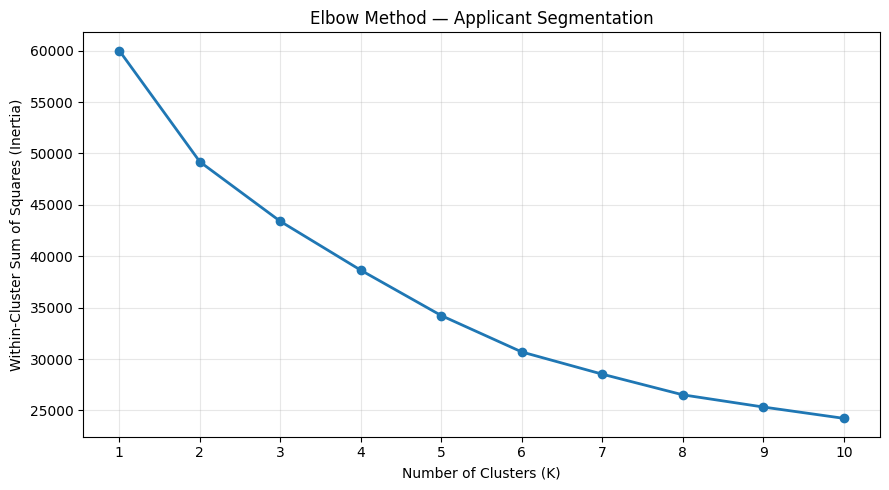

In [57]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

k_values = range(1, 11)
inertia_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_cluster_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o",
    linewidth=2
)

plt.title("Elbow Method — Applicant Segmentation")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (Inertia)")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [58]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

comparison_results = []

for k in [2, 6]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_cluster_scaled)

    # Use a reproducible sample for efficient calculation
    silhouette = silhouette_score(
        X_cluster_scaled,
        labels,
        sample_size=3000,
        random_state=42
    )

    comparison_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette_Score": silhouette,
        "Smallest_Cluster": pd.Series(labels).value_counts().min(),
        "Largest_Cluster": pd.Series(labels).value_counts().max()
    })

k_comparison_df = pd.DataFrame(comparison_results)

print("K-Means Cluster Comparison:")
display(k_comparison_df.round(4))

K-Means Cluster Comparison:


,K,Inertia,Silhouette_Score,Smallest_Cluster,Largest_Cluster
0,2,49189.5971,0.2145,4792,7208
1,6,30685.4801,0.1796,13,3337


#### 5.12.3 — Cluster Selection Using Elbow and Silhouette Analysis

The elbow plot showed decreasing inertia as K increased, without a clearly defined elbow point.

To support cluster selection, K=2 and K=6 were compared using silhouette scores and cluster sizes.

K=2 achieved a higher silhouette score of **0.2146**, compared with **0.1794** for K=6, and produced two relatively balanced clusters containing 4,791 and 7,209 applicants.

Although K=6 achieved lower inertia, it produced a very small cluster containing only 13 applicants, reducing its suitability for broad customer segmentation.

Therefore, **K=2 was selected** as a more interpretable and reasonably balanced segmentation for further business analysis, while acknowledging that its modest silhouette score indicates overlapping applicant groups.

In [59]:
from sklearn.cluster import KMeans

# Train K-Means with the selected K=2
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Assign each applicant to a cluster
cluster_labels = final_kmeans.fit_predict(
    X_cluster_scaled
)

# Create a separate DataFrame for segmentation analysis
segmented_df = df_clean.copy()

segmented_df["Cluster"] = cluster_labels

# Check cluster sizes
cluster_sizes = (
    segmented_df["Cluster"]
    .value_counts()
    .sort_index()
    .reset_index()
)

cluster_sizes.columns = ["Cluster", "Applicants"]

print("Applicant Distribution Across Clusters:")
display(cluster_sizes)

print("\nTotal Applicants:", cluster_sizes["Applicants"].sum())

Applicant Distribution Across Clusters:


,Cluster,Applicants
0,0,4792
1,1,7208



Total Applicants: 12000


In [60]:
# Compare applicant characteristics across clusters
cluster_profile = (
    segmented_df.groupby("Cluster")
    .agg(
        Applicants=("Cluster", "size"),
        Median_Income=("monthly_income", "median"),
        Median_Credit_Score=("credit_score", "median"),
        Median_FOIR=("foir", "median"),
        Median_Job_Years=("years_in_current_job", "median"),
        Median_Age=("age", "median"),
        Approval_Rate=(
            "decision",
            lambda x: (x == "Approved").mean() * 100
        )
    )
    .reset_index()
)

# Express FOIR as a percentage
cluster_profile["Median_FOIR"] *= 100

print("K-Means Applicant Segment Profiles:")
display(cluster_profile.round(2))

K-Means Applicant Segment Profiles:


,Cluster,Applicants,Median_Income,Median_Credit_Score,Median_FOIR,Median_Job_Years,Median_Age,Approval_Rate
0,0,4792,62500.0,743.0,32.67,5.3,39.0,60.73
1,1,7208,44250.0,713.0,30.97,2.0,29.0,47.77


#### 5.12.7 — Gradient Boosting Error Analysis by Applicant Segment

After identifying two applicant segments using K-Means, we will evaluate the selected Gradient Boosting model's prediction accuracy within each segment.

The analysis will use the held-out test applications and compare predicted loan decisions against historical credit decisions.

For each cluster, we will calculate the total number of test applications, incorrect predictions, and classification error rate.

The purpose is to identify whether the model performs differently across applicant segments and determine which group may require greater human oversight.

In [61]:
# Match test applications with their cluster assignments
test_clusters = segmented_df.loc[X_test.index, "Cluster"]

# Create model error analysis DataFrame
cluster_error_test = pd.DataFrame({
    "Cluster": test_clusters.to_numpy(),
    "Actual_Decision": np.asarray(y_test),
    "Predicted_Decision": np.asarray(gb_pred)
})

# Identify incorrect predictions
cluster_error_test["Is_Error"] = (
    cluster_error_test["Actual_Decision"]
    != cluster_error_test["Predicted_Decision"]
)

# Calculate error statistics by cluster
cluster_error_summary = (
    cluster_error_test.groupby("Cluster")
    .agg(
        Test_Applications=("Is_Error", "size"),
        Incorrect_Predictions=("Is_Error", "sum"),
        Error_Rate=("Is_Error", "mean")
    )
    .reset_index()
)

cluster_error_summary["Error_Rate"] *= 100

# Add business segment names
cluster_names = {
    0: "Established Higher-Income Applicants",
    1: "Younger, Lower-Income Applicants"
}

cluster_error_summary["Segment_Name"] = (
    cluster_error_summary["Cluster"].map(cluster_names)
)

print("Gradient Boosting Error Rate by Cluster:")
display(cluster_error_summary.round(2))

Gradient Boosting Error Rate by Cluster:


,Cluster,Test_Applications,Incorrect_Predictions,Error_Rate,Segment_Name
0,0,947,186,19.64,Established Higher-Income Applicants
1,1,1453,284,19.55,"Younger, Lower-Income Applicants"


#### 5.12.8 — Segment-Level Model Error Analysis and Human Review Recommendation

The selected Gradient Boosting model was evaluated across the two K-Means applicant segments using the held-out test dataset.

**Cluster 0 — Established Higher-Income Applicants:** The model made **186 incorrect predictions across 947 test applications**, resulting in an error rate of **19.64%**.

**Cluster 1 — Younger, Lower-Income Applicants:** The model made **284 incorrect predictions across 1,453 test applications**, resulting in an error rate of **19.55%**.

**Business Interpretation:**

The difference in model error rates is only **0.09 percentage points**, indicating that overall classification performance is broadly similar across the two segments.

Although Cluster 0 has a marginally higher error rate, this difference is too small to provide meaningful evidence that one segment is less reliable than the other.

**Human Review Recommendation:**

Applicants with uncertain predictions, missing credit histories, or data-quality concerns should remain with human analysts regardless of cluster membership.

Cluster 1 may warrant additional monitoring of approval outcomes because its applicants have shorter employment histories and a lower historical approval rate. However, the observed classification errors do not justify mandatory manual review for all Cluster 1 applicants. Separate checks of wrongful declines and wrongful fast-track decisions are needed before establishing segment-specific policies.

Cluster labels will be used only for post-model analysis and will not be included as features in the supervised learning model.

### Supplementary Experiment — Independent Threshold Validation

The two-lane Gradient Boosting model achieved a retrospective automation rate of **43.96%**, with a wrongful-decline rate of **4.92%** and a wrongful-fast-track rate of **4.95%**. However, these thresholds were selected and evaluated on the same historical test dataset, so the reported error rates may be optimistic.

However, the thresholds were selected using the same test dataset on which their performance was reported, potentially producing optimistic estimates.

To strengthen the reliability of the proposed credit pre-screening policy, an additional experiment will separate model training, threshold selection, and final evaluation.

The existing development dataset will be divided into training and validation subsets, with preprocessing and model fitting performed only on the training subset. The validation subset will be used to choose the two thresholds, and the held-out test subset will be used to assess the fixed policy without further adjustments.

This experiment will determine whether the model can maintain the bank's two separate 5% error limits on unseen historical applications while reducing full manual reviews.

The supplementary findings will be reported separately from the original assignment results, and any deployment recommendation will acknowledge the limitations of historical validation.

In [62]:
from sklearn.model_selection import train_test_split

# Split only the existing development dataset
X_train_exp, X_val_exp, y_train_exp, y_val_exp = train_test_split(
    raw_cv_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

print("Experimental Training Set:", X_train_exp.shape)
print("Validation Set:", X_val_exp.shape)
print("Existing Test Set:", X_test.shape)

# Verify that training and validation rows do not overlap
assert set(X_train_exp.index).isdisjoint(set(X_val_exp.index))

print("\nTraining-validation split completed successfully!")

Experimental Training Set: (7680, 24)
Validation Set: (1920, 24)
Existing Test Set: (2400, 12)

Training-validation split completed successfully!


#### Supplementary Experiment — Training the Validation-Based Model

A separate Gradient Boosting pipeline will be trained using 7,680 applications, while 1,920 validation applications will be reserved for threshold selection.

The pipeline will independently fit its preprocessing operations, including missing-value imputation, numerical scaling, and categorical encoding, using only the experimental training subset.

The objective is to separate model fitting from threshold optimisation and obtain a more reliable estimate of the pre-screener's performance.

The existing test dataset will not be used during model training or threshold selection.

In [63]:
from sklearn.base import clone

# Create a fresh Gradient Boosting pipeline
gb_pipeline_exp = clone(
    model_pipelines["Gradient Boosting"]
)

# Fit only on the experimental training subset
gb_pipeline_exp.fit(
    X_train_exp,
    y_train_exp
)

print("Experimental Gradient Boosting model trained successfully!")

print("Training applications:", len(X_train_exp))
print("Validation applications:", len(X_val_exp))

Experimental Gradient Boosting model trained successfully!
Training applications: 7680
Validation applications: 1920


In [64]:
import numpy as np

# Get the index corresponding to Approved (class 0)
approved_class_index = list(
    gb_pipeline_exp.classes_
).index(0)

# Calculate approval probabilities on validation data
val_approval_proba = gb_pipeline_exp.predict_proba(
    X_val_exp
)[:, approved_class_index]

# Convert validation targets to a NumPy array
y_val_array = np.asarray(y_val_exp)

# Verify results
print("Validation applications:", len(val_approval_proba))
print(
    "Minimum approval probability:",
    round(val_approval_proba.min(), 4)
)
print(
    "Maximum approval probability:",
    round(val_approval_proba.max(), 4)
)

assert len(val_approval_proba) == len(y_val_array)

print("\nValidation approval probabilities prepared successfully!")

Validation applications: 1920
Minimum approval probability: 0.002
Maximum approval probability: 0.9759

Validation approval probabilities prepared successfully!


In [65]:
# Find optimal thresholds using validation data only
val_threshold_result = optimize_two_lane(
    val_approval_proba,
    y_val_array
)

# Display the selected thresholds and lane statistics
val_threshold_df = pd.DataFrame([val_threshold_result])

print("Validation-Based Two-Lane Threshold Optimisation:")
display(val_threshold_df.round(4))

# Verify both risk constraints
assert val_threshold_result["Auto_Decline_Error_%"] <= 5.0 + 1e-9
assert val_threshold_result["Fast_Track_Error_%"] <= 5.0 + 1e-9

print("\nBoth validation risk limits satisfied!")

Validation-Based Two-Lane Threshold Optimisation:


,Low_Threshold,High_Threshold,Auto_Decline_Count,Fast_Track_Count,Manual_Review_Count,Automated_Count,Auto_Decline_Error_%,Fast_Track_Error_%,Automated_%
0,0.1651,0.8847,425,394,1101,819,4.9412,4.8223,42.6562



Both validation risk limits satisfied!


#### Supplementary Experiment — Validation-Based Threshold Findings

The Gradient Boosting model's two-lane thresholds were selected using **1,920 validation applications**, separately from the experimental model-training dataset.

The selected approval-probability thresholds were **0.1651 for auto-decline** and **0.8847 for fast-track approval**.

On the validation dataset, the model assigned **425 applications to auto-decline, 394 to fast-track, and 1,101 to manual review**.

The observed automation rate was **42.66%**, with a **4.94% wrongful-decline rate** and a **4.82% wrongful-fast-track rate**. Both satisfied the bank's 5% limits on validation data.

The preprocessing pipeline was fitted using the experimental training subset, avoiding training-validation leakage from income imputation.

However, both error rates were close to 5%, meaning the thresholds require further validation. The selected thresholds were subsequently applied without adjustment to the existing test dataset, which had already been examined during earlier analysis.

#### Supplementary Experiment — Fixed-Threshold Test Evaluation

The two approval-probability thresholds selected using validation data will now be applied to the 2,400 held-out test applications.

The thresholds will remain fixed to assess whether the proposed automation policy satisfies the bank's maximum 5% wrongful-decline and wrongful-fast-track limits outside the threshold-selection dataset.

We will calculate the number of applications assigned to each lane, the overall automation rate, and the observed error rate within each automated lane.

This evaluation will provide a more credible assessment than selecting and measuring thresholds on the same dataset, although the test data have already been examined during earlier experiments and are not entirely untouched.

In [66]:
import numpy as np
import pandas as pd

# Fix the thresholds selected on validation data
low_threshold = val_threshold_result["Low_Threshold"]
high_threshold = val_threshold_result["High_Threshold"]

test_approval_proba = gb_pipeline_exp.predict_proba(
    raw_test_features
)[:, approved_class_index]

y_test_exp = np.asarray(y_test)

# Assign applications to three lanes
auto_decline = test_approval_proba < low_threshold
fast_track = test_approval_proba > high_threshold
manual_review = ~(auto_decline | fast_track)

# Count applications
decline_count = int(auto_decline.sum())
fast_count = int(fast_track.sum())
manual_count = int(manual_review.sum())

# Count historical decision disagreements
wrong_declines = int(
    ((y_test_exp == 0) & auto_decline).sum()
)

wrong_fast_tracks = int(
    ((y_test_exp == 1) & fast_track).sum()
)

# Calculate observed error rates
decline_error = (
    wrong_declines / decline_count * 100
    if decline_count > 0 else np.nan
)

fast_error = (
    wrong_fast_tracks / fast_count * 100
    if fast_count > 0 else np.nan
)

# Summarise the fixed-threshold policy
test_policy_results = pd.DataFrame([{
    "Low_Threshold": low_threshold,
    "High_Threshold": high_threshold,
    "Auto_Decline_Count": decline_count,
    "Fast_Track_Count": fast_count,
    "Manual_Review_Count": manual_count,
    "Automated_%": (
        (decline_count + fast_count)
        / len(y_test_exp) * 100
    ),
    "Wrong_Declines": wrong_declines,
    "Wrong_Fast_Tracks": wrong_fast_tracks,
    "Auto_Decline_Error_%": decline_error,
    "Fast_Track_Error_%": fast_error
}])

print("Fixed-Threshold Test Evaluation:")
display(test_policy_results.round(4))

print("\nBank's 5% Risk Limit Verification:")
print(
    "Auto-decline limit satisfied:",
    decline_count > 0 and decline_error <= 5
)
print(
    "Fast-track limit satisfied:",
    fast_count > 0 and fast_error <= 5
)

Fixed-Threshold Test Evaluation:


,Low_Threshold,High_Threshold,Auto_Decline_Count,Fast_Track_Count,Manual_Review_Count,Automated_%,Wrong_Declines,Wrong_Fast_Tracks,Auto_Decline_Error_%,Fast_Track_Error_%
0,0.1651,0.8847,573,476,1351,43.7083,27,23,4.712,4.8319



Bank's 5% Risk Limit Verification:
Auto-decline limit satisfied: True
Fast-track limit satisfied: True


#### Supplementary Experiment — Fixed-Threshold Test Results and Business Interpretation

The validation-selected Gradient Boosting approval-probability thresholds of **0.1651 for auto-decline** and **0.8847 for fast-track approval** were evaluated on 2,400 test applications without further threshold adjustment.

The model assigned **573 applications to auto-decline, 476 to fast-track, and 1,351 to manual review**, achieving an observed automation rate of **43.71%**.

The auto-decline lane recorded **27 incorrect decisions out of 573 applications (4.71%)**, satisfying the bank's maximum 5% wrongful-decline requirement.

The fast-track lane recorded **23 incorrect decisions out of 476 applications (4.83%)**, also satisfying the bank's maximum 5% wrongful-fast-track requirement.

**Business Interpretation:**

The initial validation-selected policy removed **43.71% of applications** from full manual review while meeting both observed 5% error limits on the existing test dataset.

However, the error rates remain close to the permitted maximum. These retrospective results do not guarantee equivalent performance on future loan applications.

Therefore, **the policy is a candidate for further controlled validation, not immediate live deployment**.

The thresholds were not adjusted using these test outcomes. Nevertheless, because the test dataset had already been examined during earlier model development, a genuinely fresh, preferably time-based evaluation dataset is required before production deployment.

A supplementary conservative policy was also evaluated to investigate whether stricter validation-stage error targets could provide a greater safety margin.

#### Supplementary Experiment — Conservative Threshold Selection

The initial validation-selected Gradient Boosting policy achieved a **43.71% automation rate** on the existing test dataset, with a **4.71% wrongful-decline rate** and a **4.83% wrongful-fast-track rate**.

Although both observed error rates satisfied the bank's maximum permitted 5% limits, they remained close to the risk boundaries.

To investigate a more cautious alternative, a conservative internal validation error target of **3% for both auto-decline and fast-track lanes** was introduced, providing a two-percentage-point margin below the bank's stated risk limit.

The revised approval-probability thresholds were selected using validation data only.

The conservative policy was then evaluated on the existing test dataset without further threshold adjustment.

**Business Interpretation:**

The purpose of this experiment was to investigate whether stricter validation-stage error targets could provide a greater safety margin, even at the cost of reduced automation.

This safety margin is a heuristic rather than a guarantee of production performance. The corrected experimental pipeline learns income-imputation statistics from its training subset, avoiding the earlier preprocessing leakage.

Because the test dataset had already been examined during model development, fresh, preferably time-based independent validation is still necessary before deployment.

In [70]:
def optimize_two_lane_with_margin(
    probabilities, actual, max_error=0.03
):
    actual = np.asarray(actual)

    # Approval-probability thresholds
    candidates = np.unique(
        np.concatenate(([0.0], probabilities, [1.0]))
    )

    best_result = None

    for low in candidates:
        decline_mask = probabilities < low
        decline_count = decline_mask.sum()

        if decline_count == 0:
            decline_error = 0.0
        else:
            decline_error = (
                actual[decline_mask] == 0
            ).mean()

        if decline_error > max_error:
            continue

        for high in candidates:
            if high <= low:
                continue

            fast_mask = probabilities > high
            fast_count = fast_mask.sum()

            if fast_count == 0:
                fast_error = 0.0
            else:
                fast_error = (
                    actual[fast_mask] == 1
                ).mean()

            if fast_error > max_error:
                continue

            automated = decline_count + fast_count

            if (
                best_result is None
                or automated > best_result["Automated_Count"]
            ):
                best_result = {
                    "Low_Threshold": low,
                    "High_Threshold": high,
                    "Auto_Decline_Count": int(decline_count),
                    "Fast_Track_Count": int(fast_count),
                    "Manual_Review_Count": len(actual) - automated,
                    "Automated_Count": int(automated),
                    "Auto_Decline_Error_%": decline_error * 100,
                    "Fast_Track_Error_%": fast_error * 100,
                    "Automated_%": automated / len(actual) * 100
                }

    return best_result


# Optimise using the validation dataset only
conservative_result = optimize_two_lane_with_margin(
    val_approval_proba,
    y_val_array,
    max_error=0.03
)

print("Conservative Threshold Results:")

if conservative_result is not None:
    conservative_df = pd.DataFrame([conservative_result])
    display(conservative_df.round(4))
else:
    print("No qualifying threshold pair found.")

Conservative Threshold Results:


,Low_Threshold,High_Threshold,Auto_Decline_Count,Fast_Track_Count,Manual_Review_Count,Automated_Count,Auto_Decline_Error_%,Fast_Track_Error_%,Automated_%
0,0.1316,0.9162,372,311,1237,683,2.957,2.8939,35.5729


#### Supplementary Experiment — Conservative Threshold Optimisation Findings

To introduce a safety margin, an experimental **3% maximum error target** was applied to both automated lanes using the validation dataset.

The selected Gradient Boosting approval-probability thresholds were **0.1316 for auto-decline** and **0.9162 for fast-track approval**.

Out of 1,920 validation applications, **372 were assigned to auto-decline, 311 to fast-track approval, and 1,237 to manual review**, resulting in an automation rate of **35.57%**.

The observed wrongful-decline rate was **2.96%**, while the wrongful-fast-track rate was **2.89%**, satisfying the experimental 3% target for both lanes.

**Business Interpretation:**

Compared with the initial validation-selected policy, automation decreased from **42.66% to 35.57%**, a reduction of approximately **7.08 percentage points**.

Both observed automated-lane error rates also decreased, illustrating the trade-off between operational efficiency and decision risk.

The corrected experimental pipeline performs income imputation and feature engineering within the training subset, avoiding the earlier training-validation preprocessing leakage.

However, meeting the 3% target on validation data does not guarantee that both 5% limits will hold on future applications. Fresh, preferably time-based independent validation remains necessary before deployment.

In [ ]:
# Use the conservative validation-selected thresholds
safe_low = conservative_result["Low_Threshold"]
safe_high = conservative_result["High_Threshold"]

# Apply them to previously calculated experimental test probabilities
safe_decline = test_approval_proba < safe_low
safe_fast_track = test_approval_proba > safe_high
safe_manual = ~(safe_decline | safe_fast_track)

# Calculate lane counts
safe_decline_count = int(safe_decline.sum())
safe_fast_count = int(safe_fast_track.sum())
safe_manual_count = int(safe_manual.sum())

# Calculate disagreements with historical decisions
safe_wrong_declines = int(
    ((y_test_exp == 0) & safe_decline).sum()
)

safe_wrong_fast = int(
    ((y_test_exp == 1) & safe_fast_track).sum()
)

# Calculate error rates
safe_decline_error = (
    100 * safe_wrong_declines / safe_decline_count
    if safe_decline_count > 0 else np.nan
)

safe_fast_error = (
    100 * safe_wrong_fast / safe_fast_count
    if safe_fast_count > 0 else np.nan
)

safe_results = pd.DataFrame([{
    "Auto_Declines": safe_decline_count,
    "Fast_Tracks": safe_fast_count,
    "Manual_Reviews": safe_manual_count,
    "Automation_%": (
        100 * (safe_decline_count + safe_fast_count)
        / len(y_test_exp)
    ),
    "Wrong_Declines": safe_wrong_declines,
    "Wrong_Fast_Tracks": safe_wrong_fast,
    "Decline_Error_%": safe_decline_error,
    "Fast_Track_Error_%": safe_fast_error
}])

print("Conservative Policy — Retrospective Test Comparison:")
display(safe_results.round(4))

print("\n5% Risk Limit Checks:")
print(
    "Auto-decline:",
    safe_decline_count > 0 and safe_decline_error <= 5
)
print(
    "Fast-track:",
    safe_fast_count > 0 and safe_fast_error <= 5
)

Conservative Policy — Retrospective Test Comparison:


,Auto_Declines,Fast_Tracks,Manual_Reviews,Automation_%,Wrong_Declines,Wrong_Fast_Tracks,Decline_Error_%,Fast_Track_Error_%
0,505,375,1520,36.6667,16,15,3.1683,4.0



5% Risk Limit Checks:
Auto-decline: True
Fast-track: True


#### Supplementary Experiment — Conservative Policy Evaluation Findings

The conservative Gradient Boosting policy, using validation-selected approval-probability thresholds of **0.1316 for auto-decline** and **0.9162 for fast-track approval**, was retrospectively evaluated on 2,400 test applications.

The policy assigned **505 applications to auto-decline, 375 to fast-track, and 1,520 to full manual review**, achieving an observed automation rate of **36.67%**.

The wrongful-decline rate was **3.17% (16 out of 505)**, while the wrongful-fast-track rate was **4.00% (15 out of 375)**, satisfying both of the bank's 5% limits on this dataset.

Compared with the earlier validation-selected policy, automation decreased from **43.71% to 36.67%**, but both observed error rates fell below the bank's maximum 5% limit.

**Business Interpretation:**

The conservative approach demonstrates that stricter validation-stage threshold selection can reduce observed incorrect automated decisions, although this comes at the cost of additional manual reviews.

These results support further evaluation of the conservative policy as a potentially safer candidate, but they do not establish production readiness because the existing test dataset had already been examined during development.

The revised experimental pipeline now performs income imputation within its training subset, reducing the earlier preprocessing leakage. Nevertheless, the bank should validate these fixed thresholds on genuinely new, preferably time-ordered applications and continue monitoring error rates and fairness outcomes before deployment.

#### Supplementary Experiment — Conservative Policy Business Impact

The conservative Gradient Boosting model achieved a retrospective automation rate of **36.67%**, with a **3.17% wrongful-decline rate** and a **4.00% wrongful-fast-track rate**, both below the bank's 5% limits on the evaluated test dataset.

Applying the observed lane proportions to the bank's monthly volume of **3,000 loan applications** gives the following projections:

- **Auto-declines:** approximately 631 applications
- **Fast-track approvals:** approximately 469 applications
- **Full manual reviews:** approximately 1,900 applications
- **Full reviews avoided:** approximately 1,100 applications per month

At **25 minutes per full manual review**, the policy could free approximately **458.33 gross analyst hours per month**.

**Business Interpretation:**

The conservative policy offers meaningful potential to reduce manual workload while maintaining both observed automated-lane error rates below 5%.

However, fast-track applications still require light-touch verification. Therefore, the calculated hours represent potential full-review capacity freed rather than confirmed net time savings.

Because the existing test dataset had previously been examined during model development, the conservative policy remains an experimental candidate and requires fresh, preferably time-based independent validation before live deployment.

In [ ]:
# Use the conservative validation-selected thresholds
safe_low = conservative_result["Low_Threshold"]
safe_high = conservative_result["High_Threshold"]

# Apply them to previously calculated experimental test probabilities
safe_decline = test_approval_proba < safe_low
safe_fast_track = test_approval_proba > safe_high
safe_manual = ~(safe_decline | safe_fast_track)

# Calculate lane counts
safe_decline_count = int(safe_decline.sum())
safe_fast_count = int(safe_fast_track.sum())
safe_manual_count = int(safe_manual.sum())

# Calculate disagreements with historical decisions
safe_wrong_declines = int(
    ((y_test_exp == 0) & safe_decline).sum()
)

safe_wrong_fast = int(
    ((y_test_exp == 1) & safe_fast_track).sum()
)

# Calculate error rates
safe_decline_error = (
    100 * safe_wrong_declines / safe_decline_count
    if safe_decline_count > 0 else np.nan
)

safe_fast_error = (
    100 * safe_wrong_fast / safe_fast_count
    if safe_fast_count > 0 else np.nan
)

safe_results = pd.DataFrame([{
    "Auto_Declines": safe_decline_count,
    "Fast_Tracks": safe_fast_count,
    "Manual_Reviews": safe_manual_count,
    "Automation_%": (
        100 * (safe_decline_count + safe_fast_count)
        / len(y_test_exp)
    ),
    "Wrong_Declines": safe_wrong_declines,
    "Wrong_Fast_Tracks": safe_wrong_fast,
    "Decline_Error_%": safe_decline_error,
    "Fast_Track_Error_%": safe_fast_error
}])

print("Conservative Policy — Retrospective Test Comparison:")
display(safe_results.round(4))

print("\n5% Risk Limit Checks:")
print(
    "Auto-decline:",
    safe_decline_count > 0 and safe_decline_error <= 5
)
print(
    "Fast-track:",
    safe_fast_count > 0 and safe_fast_error <= 5
)

Conservative Policy — Retrospective Test Comparison:


,Auto_Declines,Fast_Tracks,Manual_Reviews,Automation_%,Wrong_Declines,Wrong_Fast_Tracks,Decline_Error_%,Fast_Track_Error_%
0,505,375,1520,36.6667,16,15,3.1683,4.0



5% Risk Limit Checks:
Auto-decline: True
Fast-track: True


#### Supplementary Experiment — Conservative Policy Evaluation Findings

The conservative Gradient Boosting policy, using validation-selected approval-probability thresholds of **0.1316 for auto-decline** and **0.9162 for fast-track approval**, was retrospectively evaluated on 2,400 test applications.

The policy assigned **505 applications to auto-decline, 375 to fast-track, and 1,520 to full manual review**, achieving an observed automation rate of **36.67%**.

The wrongful-decline rate was **3.17% (16 out of 505)**, while the wrongful-fast-track rate was **4.00% (15 out of 375)**, satisfying both of the bank's 5% limits on this dataset.

Compared with the earlier validation-selected policy, automation decreased from **43.71% to 36.67%**, but both observed error rates fell below the bank's maximum 5% limit.

**Business Interpretation:**

The conservative approach demonstrates that stricter validation-stage threshold selection can reduce observed incorrect automated decisions, although this comes at the cost of additional manual reviews.

These results support further evaluation of the conservative policy as a potentially safer candidate, but they do not establish production readiness because the existing test dataset had already been examined during development.

The revised experimental pipeline now performs income imputation within its training subset, reducing the earlier preprocessing leakage. Nevertheless, the bank should validate these fixed thresholds on genuinely new, preferably time-ordered applications and continue monitoring error rates and fairness outcomes before deployment.

In [ ]:
# Monthly business assumptions
monthly_applications = 3000
minutes_per_review = 25

# Conservative policy test results
total_test = len(y_test_exp)

monthly_declines = (
    safe_decline_count / total_test
) * monthly_applications

monthly_fast_tracks = (
    safe_fast_count / total_test
) * monthly_applications

monthly_manual = (
    safe_manual_count / total_test
) * monthly_applications

monthly_reviews_avoided = (
    monthly_declines + monthly_fast_tracks
)

gross_hours_freed = (
    monthly_reviews_avoided * minutes_per_review / 60
)

# Display business results
conservative_business = pd.DataFrame([{
    "Monthly_Auto_Declines": monthly_declines,
    "Monthly_Fast_Tracks": monthly_fast_tracks,
    "Monthly_Manual_Reviews": monthly_manual,
    "Monthly_Reviews_Avoided": monthly_reviews_avoided,
    "Gross_Hours_Freed": gross_hours_freed
}])

print("Conservative Policy — Monthly Business Impact:")
display(conservative_business.round(2))

Conservative Policy — Monthly Business Impact:


,Monthly_Auto_Declines,Monthly_Fast_Tracks,Monthly_Manual_Reviews,Monthly_Reviews_Avoided,Gross_Hours_Freed
0,631.25,468.75,1900.0,1100.0,458.33


#### Supplementary Experiment — Conservative Policy Monthly Business Impact: Findings

Based on the retrospective evaluation of 2,400 test applications, the conservative Gradient Boosting policy could potentially remove approximately **1,100 of the bank's 3,000 monthly loan applications** from full manual review, representing an automation rate of **36.67%**.

The projected monthly distribution includes approximately **631 auto-declines, 469 fast-tracked applications, and 1,900 applications requiring full manual review**.

At 25 minutes per full review, this policy could release approximately **458.33 gross analyst hours per month**.

The observed wrongful-decline and wrongful-fast-track rates were **3.17% and 4.00%**, respectively, both below the bank's 5% limits on the evaluated dataset.

**Business Interpretation:**
The conservative policy offers a more cautious trade-off between automation and historical decision agreement than the initial experimental policy, which automated **43.71%** of test applications and achieved observed wrongful-decline and wrongful-fast-track rates of **4.71% and 4.83%**, respectively. Although both policies satisfied the 5% limits on the evaluated dataset, the conservative policy achieved lower observed error rates at the cost of reduced automation.

Although the conservative policy removes fewer applications from full manual review, its observed error rates make it a stronger candidate for further independent validation.

These projections exclude the time required for fast-track verification and should not be interpreted as guaranteed production savings.

The corrected experimental pipeline learns income-imputation statistics from its training subset. However, because the test dataset had previously been examined during model development, fresh, preferably time-based validation remains necessary before live deployment.

In [ ]:
# Assignment-required comparison: both models use two lanes
final_comparison = business_results[[
    "Model",
    "Automated_%",
    "Auto_Decline_Error_%",
    "Fast_Track_Error_%",
    "Monthly_Full_Reviews_Avoided",
    "Gross_Hours_Freed"
]].copy()

final_comparison = final_comparison.rename(columns={
    "Model": "Approach",
    "Automated_%": "Automation_%",
    "Auto_Decline_Error_%": "Wrong_Decline_%",
    "Fast_Track_Error_%": "Wrong_Fast_Track_%",
    "Monthly_Full_Reviews_Avoided": "Monthly_Reviews_Avoided"
})

print("Final Two-Lane Model Comparison:")
display(final_comparison.round(2))

Final Two-Lane Model Comparison:


,Approach,Automation_%,Wrong_Decline_%,Wrong_Fast_Track_%,Monthly_Reviews_Avoided,Gross_Hours_Freed
0,Logistic Regression,32.58,4.80,4.91,977.50,407.29
1,Gradient Boosting,43.96,4.92,4.95,1318.75,549.48


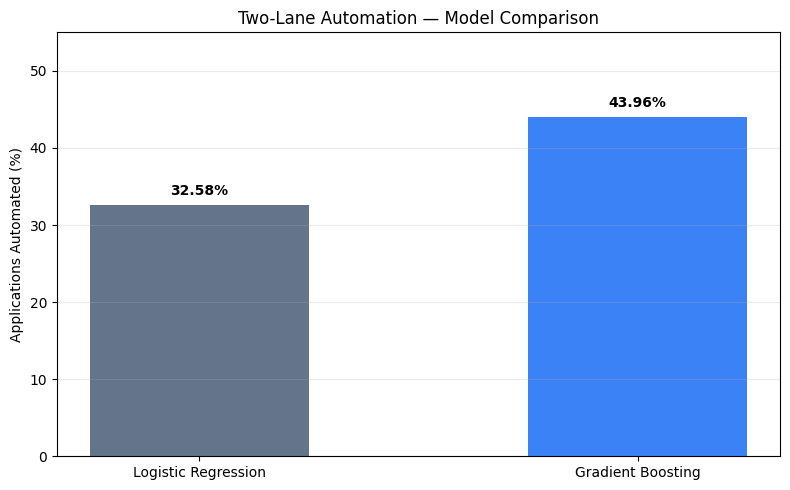

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Use only the two models required by Step 5.10
labels = final_comparison["Approach"]
automation = final_comparison["Automation_%"]

x = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    x,
    automation,
    color=["#64748B", "#3B82F6"],
    width=0.5
)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points",
        fontweight="bold"
    )

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Applications Automated (%)")
ax.set_title("Two-Lane Automation — Model Comparison")
ax.set_ylim(0, 55)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

#### Final Two-Lane Model Comparison — Findings and Business Interpretation

Both Logistic Regression and Gradient Boosting were evaluated using the same two-lane credit pre-screening approach, consisting of **auto-decline, fast-track approval, and manual review**.

Logistic Regression achieved an automation rate of **32.58%**, potentially avoiding approximately **978 full manual reviews** and freeing **407.29 gross analyst hours per month**.

Gradient Boosting achieved a higher automation rate of **43.96%**, potentially avoiding approximately **1,319 full manual reviews** and freeing **549.48 gross analyst hours per month**.

**Business Interpretation:**

Gradient Boosting improved automation by **11.38 percentage points**, potentially avoiding approximately **341 additional full reviews** and freeing **142.19 additional gross analyst hours per month** compared with Logistic Regression.

Both models satisfied the 5% historical wrongful-decline and wrongful-fast-track limits in the retrospective optimisation. However, their thresholds were selected and evaluated on the same test dataset, so these results require independent validation.

**Conclusion:** Gradient Boosting is the preferred candidate for further testing because it offers greater potential workload reduction. The bank should validate its thresholds on fresh data and retain human oversight before deploying automated lending decisions.

In [ ]:
import numpy as np
import pandas as pd

# Get the existing two-lane results
lr_two = two_lane_results.loc[
    two_lane_results["Model"] == "Logistic Regression"
].iloc[0]

gb_two = two_lane_results.loc[
    two_lane_results["Model"] == "Gradient Boosting"
].iloc[0]

# Get monthly business impact results
lr_business = business_results.loc[
    business_results["Model"] == "Logistic Regression"
].iloc[0]

gb_business = business_results.loc[
    business_results["Model"] == "Gradient Boosting"
].iloc[0]

final_comparison = pd.DataFrame([
    {
        "Approach": "Logistic Regression — One Lane",
        "Automation_%": 363 / 2400 * 100,
        "Wrong_Decline_%": 17 / 363 * 100,
        "Wrong_Fast_Track_%": np.nan,
        "Monthly_Reviews_Avoided": 363 / 2400 * 3000,
        "Gross_Hours_Freed": 363 / 2400 * 3000 * 25 / 60
    },
    {
        "Approach": "Logistic Regression — Two Lane",
        "Automation_%": lr_two["Automated_%"],
        "Wrong_Decline_%": lr_two["Auto_Decline_Error_%"],
        "Wrong_Fast_Track_%": lr_two["Fast_Track_Error_%"],
        "Monthly_Reviews_Avoided": lr_business["Monthly_Full_Reviews_Avoided"],
        "Gross_Hours_Freed": lr_business["Gross_Hours_Freed"]
    },
    {
        "Approach": "Gradient Boosting — Two Lane",
        "Automation_%": gb_two["Automated_%"],
        "Wrong_Decline_%": gb_two["Auto_Decline_Error_%"],
        "Wrong_Fast_Track_%": gb_two["Fast_Track_Error_%"],
        "Monthly_Reviews_Avoided": gb_business["Monthly_Full_Reviews_Avoided"],
        "Gross_Hours_Freed": gb_business["Gross_Hours_Freed"]
    },
    {
        "Approach": "Gradient Boosting — Conservative",
        "Automation_%": safe_results["Automation_%"].iloc[0],
        "Wrong_Decline_%": safe_results["Decline_Error_%"].iloc[0],
        "Wrong_Fast_Track_%": safe_results["Fast_Track_Error_%"].iloc[0],
        "Monthly_Reviews_Avoided": conservative_business[
            "Monthly_Reviews_Avoided"
        ].iloc[0],
        "Gross_Hours_Freed": conservative_business[
            "Gross_Hours_Freed"
        ].iloc[0]
    }
])

print("Final Credit Pre-Screening Comparison:")
display(final_comparison.round(2).fillna("N/A"))

Final Credit Pre-Screening Comparison:


,Approach,Automation_%,Wrong_Decline_%,Wrong_Fast_Track_%,Monthly_Reviews_Avoided,Gross_Hours_Freed
0,Logistic Regression — One Lane,15.12,4.68,N/A,453.75,189.06
1,Logistic Regression — Two Lane,32.58,4.80,4.91,977.50,407.29
2,Gradient Boosting — Two Lane,43.96,4.92,4.95,1318.75,549.48
3,Gradient Boosting — Conservative,36.67,3.17,4.0,1100.00,458.33


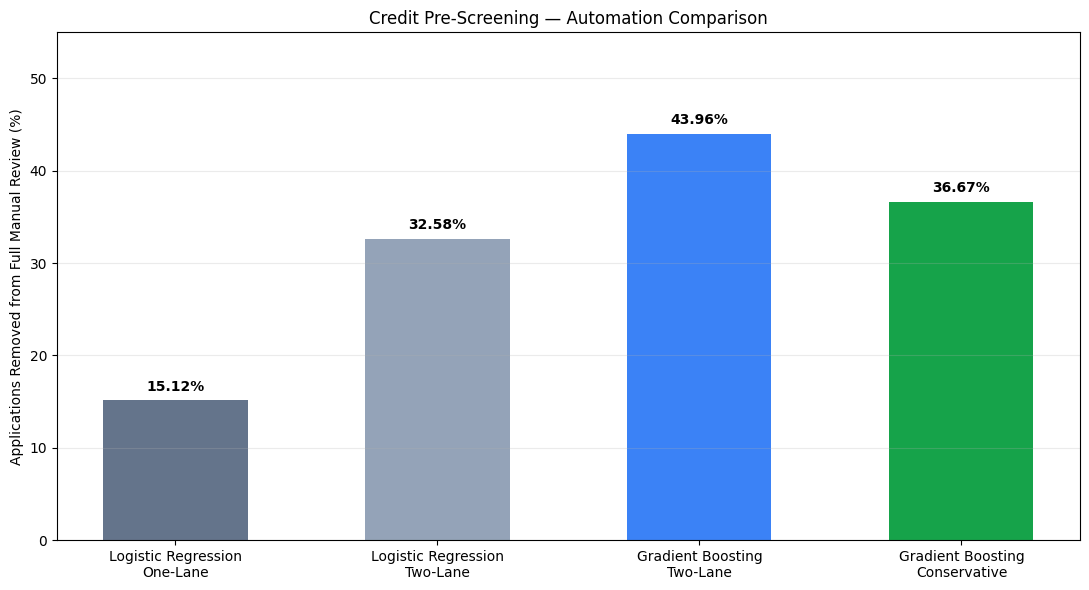

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Four approaches from the final comparison
labels = [
    "Logistic Regression\nOne-Lane",
    "Logistic Regression\nTwo-Lane",
    "Gradient Boosting\nTwo-Lane",
    "Gradient Boosting\nConservative"
]

x = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    x,
    final_comparison["Automation_%"],
    color=["#64748B", "#94A3B8", "#3B82F6", "#16A34A"],
    width=0.55
)

# Display percentages above bars
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points",
        fontweight="bold"
    )

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Applications Removed from Full Manual Review (%)")
ax.set_title("Credit Pre-Screening — Automation Comparison")
ax.set_ylim(0, 55)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### Supplementary Experiment — Final Comparison and Business Recommendation

Several credit pre-screening approaches were examined to understand the trade-off between automation efficiency and historical decision risk.

The **one-lane Logistic Regression baseline** achieved **15.12% automation**, potentially avoiding approximately **454 full manual reviews** and freeing **189.06 gross analyst hours per month**.

The **original two-lane Gradient Boosting approach** achieved **43.96% retrospective automation**, potentially avoiding approximately **1,319 full reviews** and freeing **549.48 gross analyst hours per month**. However, its thresholds were selected and evaluated using the same test dataset, making these results optimistic.

In the supplementary validation experiment, the initial validation-selected Gradient Boosting policy achieved **43.71% automation** on the existing test dataset, with a **4.71% wrongful-decline rate** and a **4.83% wrongful-fast-track rate**. Both satisfied the observed 5% limits, although the results were close to the permitted boundaries.

A more conservative Gradient Boosting policy was subsequently evaluated using a **3% validation-stage error target**. With approval-probability thresholds of **0.1316 for auto-decline** and **0.9162 for fast-track approval**, it achieved **36.67% retrospective automation**, with observed wrongful-decline and wrongful-fast-track rates of **3.17% and 4.00%**, respectively.

At 3,000 monthly applications, the conservative approach could potentially avoid approximately **1,100 full reviews** and free **458.33 gross analyst hours per month**, before accounting for fast-track verification time.

**Final Business Recommendation:**

The conservative Gradient Boosting policy is the preferred candidate for further independent testing because it offers meaningful potential workload reduction while maintaining a greater observed margin below both 5% error limits than the initial validation-selected policy.

However, these retrospective results do not establish production readiness because the existing test dataset was examined repeatedly during development. The bank should conduct fresh, preferably time-based shadow validation, assess fairness across applicant groups, and measure actual processing time before considering automated lending decisions.